# Ejercicio Práctico — Semana 2: Red de organizaciones de GitHub: estructura, robustez, comunidades y recomendación

**Asignatura:** Inteligencia Artificial: Data Mining II — Maestría en Ciencias de Datos y Máquinas de Aprendizaje, mención IA (UIDE)
**Docente:** Miguel Angel Rosero Aguas
**Cubre:** Sesión 1 — Grafos, centralidad, conectividad y robustez  /  Sesión 2 — Comunidades, caminos, robustez y recomendación
**Grupo N.º:** 9

| # | Integrante | Rol en el equipo |
|---|---|---|
| 1 |Rodrigo Soria  | |
| 2 |Kevin Ambuludi | |
| 3 |Christian Ruiz| |


## Índice

1. [Carga, limpieza y modelado como grafo](#fase-1)
2. [Proyección y visualización](#fase-2)
3. [Centralidades](#fase-3)
4. [Componentes conectados y propiedades de la red](#fase-4)
5. [Resiliencia y robustez](#fase-5)
6. [Caminos: BFS, DFS, Dijkstra y Floyd-Warshall](#fase-6)
7. [Detección de comunidades](#fase-7)
8. [Sistema de recomendación y desafío](#fase-8)
9. [Tendencias: backends de NetworkX y GraphRAG](#fase-9)
10. [Fase final: aplicación al entorno profesional](#fase-final)

## Estructura del ejercicio

Este notebook va con la guía **Ejercicio_Practico_Semana2_Guia.docx**: el código y los gráficos se hacen aquí; en la guía responden por escrito
la **pregunta de cada fase** (la misma que aparece abajo de cada título) y la fase final individual.

| Bloque | Fases | Qué entregan |
|---|---|---|
| Datos y exploración | 1–3 | código + conclusión en el notebook; respuesta en la guía |
| Modelado y análisis | 4–7 | código + conclusión en el notebook; respuesta en la guía |
| Desafío y tendencias | 8–9 | evidencia en el notebook; respuesta en la guía |
| Aplicación profesional | final | una respuesta por integrante (notebook y guía) |

**Entrega en Canvas:** este notebook ejecutado y la guía completada (Word o PDF).

## Contexto

Una fundación de software libre quiere entender cómo se conectan 41 organizaciones de GitHub (Microsoft, Google, Apache, Node.js…) a través de los desarrolladores que comparten. Los desarrolladores que pertenecen a varias organizaciones son los **nodos puente** del ecosistema: transfieren conocimiento y sostienen proyectos comunes. Ustedes deben modelar la red con NetworkX, medir su estructura y su robustez, encontrar comunidades y proponer un recomendador de organizaciones.

**Dataset:** GitHub Organizations – Social Network Analysis (Kaggle, anshulmehtakaggl): https://www.kaggle.com/datasets/anshulmehtakaggl/github-organizations-social-network-analysis (organization.csv: columnas Organisation, member)

## Desafío

1) Identificar las **3 organizaciones (o desarrolladores) puente** cuya salida más fragmentaría la red, con evidencia de centralidad y de la simulación de robustez. 2) Construir un **recomendador** que sugiera a cada desarrollador multi-organización una organización nueva, y medir su calidad ocultando membresías reales (hit@k). 3) **Comparar** al menos tres algoritmos de comunidades y argumentar cuál usarían y por qué. 4) Declarar una implicación ética de analizar redes de personas reales.

> **Formato de entrega:** un único `.ipynb` ejecutado. Código limpio y comentado. Antes de cada gráfico,
> una línea que diga qué se analiza; después, la conclusión de negocio. Nombre del archivo:
> `grupoN_Semana2_Ejercicio.ipynb`.

In [1]:
# ===== Entorno: el mismo notebook corre en Google Colab y en local =====
import importlib, os, shutil, subprocess, sys, urllib.request   # utilidades: instalar paquetes, rutas y descargas
from pathlib import Path                            # rutas iguales en Windows, Linux y Colab

EN_COLAB = "google.colab" in sys.modules           # True si estamos dentro de Colab
print("Entorno:", "Google Colab" if EN_COLAB else "local", "| Python", sys.version.split()[0])   # dónde corre y qué Python

# Instalamos solo los paquetes que falten. El nombre en pip no siempre es el del import:
# ej.: pip install scikit-learn -> import sklearn; nx-parallel -> nx_parallel
IMPORT_DE = {"scikit-learn": "sklearn", "sentence-transformers": "sentence_transformers",   # nombre en pip -> nombre del import
             "delta-spark": "delta", "python-calamine": "python_calamine",   # instaladores y lectores de Excel
             "python-louvain": "community", "imbalanced-learn": "imblearn"}   # comunidades y desbalance de clases
for pip_nombre in ['kagglehub', 'nx-parallel']:   # paquetes que necesita esta práctica
    base = pip_nombre.split("==")[0].split(">=")[0]                    # ej.: "networkx>=3.7" -> "networkx"
    modulo = IMPORT_DE.get(base, base.replace("-", "_"))   # nombre del import. Ej.: nx-parallel -> nx_parallel
    if importlib.util.find_spec(modulo) is None:   # solo si NO está instalado (Colab ya trae muchos)
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_nombre])   # Colab y venv con pip
        if r.returncode != 0 and shutil.which("uv"):                   # venv creado con uv (no trae pip)
            r = subprocess.run(["uv", "pip", "install", "-q", "--python", sys.executable, pip_nombre])   # instala con uv en este mismo Python
        if r.returncode != 0:   # ni pip ni uv pudieron instalarlo
            raise RuntimeError(f"Instala '{pip_nombre}' en este entorno (pip/uv) y vuelve a ejecutar")   # error explícito con la acción a seguir
        importlib.invalidate_caches()                                  # para que el import vea el paquete recién instalado

# Carpeta de datos relativa: en Colab es /content/data, en local ./data
DATA = Path("data"); DATA.mkdir(exist_ok=True)   # crea la carpeta si no existe

def descargar(url, nombre):   # Ej.: descargar(URL, "telco.csv") -> data/telco.csv
    # Descarga una sola vez; si el archivo ya existe, no vuelve a bajarlo
    destino = DATA / nombre   # ruta local del archivo. Ej.: data/telco.csv
    if not destino.exists():   # descarga solo la primera vez
        print("Descargando", nombre, "...")   # aviso de progreso
        urllib.request.urlretrieve(url, destino)   # descarga el archivo en data/
    return destino   # devuelve la ruta para usarla después

ARCHIVOS = [   # lista de (url, nombre) que usa esta práctica
    
]
for url, nombre in ARCHIVOS:   # descarga cada archivo
    print(nombre, "->", round(descargar(url, nombre).stat().st_size / 1e6, 2), "MB")   # y muestra su tamaño en MB

Entorno: local | Python 3.12.13


In [2]:
# ===== Estilo de gráficos (principios de Tufte): alta proporción dato-tinta, un solo color de acento =====
import matplotlib.pyplot as plt                     # gráficos
from cycler import cycler                           # orden de colores por defecto
TINTA, ACENTO, GRIS = "#14323F", "#E89B2E", "#B7C3C9"     # tokens del módulo; ACENTO = color de esta semana
plt.rcParams.update({   # estilo por defecto de todos los gráficos
    "axes.spines.top": False, "axes.spines.right": False,    # sin marco: solo los ejes necesarios
    "axes.grid": False, "axes.edgecolor": GRIS,              # sin rejilla (las etiquetas dicen el valor)
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlecolor": TINTA,   # títulos a la izquierda y en negrita
    "axes.prop_cycle": cycler(color=[TINTA, ACENTO, GRIS, "#5B6B73"]),
    "font.size": 12, "legend.frameon": False, "figure.dpi": 110,   # letra legible, leyenda sin caja, nitidez
})
# Regla práctica: pinten con ACENTO solo el dato que quieren que el lector mire; el resto en GRIS.

<a id="fase-1"></a>
## Fase 1: Carga, limpieza y modelado como grafo

Paso 1 del enunciado. Carguen `organization.csv`, cuantifiquen nulos y duplicados y documenten la limpieza. Modelen la red como **grafo bipartito** organización–miembro y justifiquen por qué esa representación (y no otra) es la adecuada. Reporten nodos, aristas, densidad y cuántos miembros pertenecen a más de una organización.

> **Pregunta de la guía:** Nodos, aristas, densidad y n.º de miembros multi-organización. ¿Por qué un grafo bipartito?

**Qué analizamos:** Evaluamos la calidad del dataset organization.csv cuantificando valores nulos y registros duplicados para documentar y ejecutar su limpieza. Posteriormente, modelamos la red utilizando un grafo bipartito (separando estrictamente los nodos en dos conjuntos disjuntos: organizaciones y desarrolladores), ya que refleja la arquitectura real de las relaciones de membresía en GitHub. Finalmente, extraemos las métricas estructurales base y el volumen de desarrolladores que actúan como puentes (grado > 1).

In [3]:
# Instalación protegida: solo se instalan los paquetes que faltan y un fallo no detiene el notebook
import importlib.util, subprocess, sys

REQUERIDOS = {"pandas": "pandas", "networkx": "networkx", "numpy": "numpy", "matplotlib": "matplotlib",
              "scipy": "scipy", "kagglehub": "kagglehub", "sklearn": "scikit-learn",
              "community": "python-louvain", "nx_parallel": "nx-parallel",
              "transformers": "transformers", "torch": "torch"}   # import -> nombre en pip
faltan = [pip for mod, pip in REQUERIDOS.items() if importlib.util.find_spec(mod) is None]
if faltan:
    print("Instalando:", faltan)
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", *faltan])
    except Exception as e:   # sin pip (p. ej. venv de uv): se informa y se continúa
        print("No se pudo instalar automáticamente", faltan, "->", e)
else:
    print("Todos los paquetes requeridos ya están instalados.")


Todos los paquetes requeridos ya están instalados.


In [4]:
import pandas as pd, networkx as nx, numpy as np
from networkx.algorithms import bipartite
SEMILLA = 42
print('networkx', nx.__version__, '| pandas', pd.__version__)

import kagglehub
ruta = kagglehub.dataset_download('anshulmehtakaggl/github-organizations-social-network-analysis')
df = pd.read_csv(f'{ruta}/organization.csv')

# 1. Cuantificar nulos y duplicados
print("--- Calidad de Datos Inicial ---")
print(f"Valores nulos:\n{df.isnull().sum()}")
print(f"\nFilas duplicadas: {df.duplicated().sum()}")

# 2. Documentar y ejecutar limpieza
# Decisión: Eliminar duplicados absolutos (mismo miembro listado en la misma org varias veces) y descartar filas con nulos.
df_clean = df.dropna().drop_duplicates()
print(f"\nDatos limpios -> Filas útiles: {df_clean.shape[0]}")

# 2b. Normalizar nombres de nodos
#     Organizaciones: minúsculas, sin espacios ni puntos. Ej.: "Azure" -> "azure", "NVIDIA" -> "nvidia"
#     Miembros: SOLO se quitan espacios al inicio y al final. Ej.: "sarah " -> "sarah" ("Sarah" sigue siendo otro nodo)
#     Decisión del equipo: no pasamos los miembros a minúsculas. Esa fusión unía nombres de pila de personas
#     distintas (Dan/dan, Ben/ben, Chris/chris, Greg/greg, Lin/lin, Lei Xu/LeiXu, Sarah/"sarah ") y creaba
#     aristas falsas en la proyección (p. ej. google-facebook y google-reactjs), que cambiaban el 3.er puente.
import re
def normalizar(nombre):
    return re.sub(r"[\s\.]+", "", str(nombre).strip().lower())

print("\n--- Normalización de nombres (conteo antes -> después) ---")
# Organizaciones: normalización completa
orgs_antes = df_clean['Organisation'].unique()
grupos_org = pd.Series(orgs_antes).groupby(pd.Series(orgs_antes).map(normalizar)).apply(list)
fusion_org = grupos_org[grupos_org.map(len) > 1]
print(f"Organisation: {len(orgs_antes)} nombres únicos -> {len(grupos_org)} tras normalizar "
      f"({len(fusion_org)} grupos de variantes fusionados)")
for clave, variantes in fusion_org.items():
    print(f"   {clave!r} <- {sorted(variantes)}")

# Miembros: solo strip (sin minúsculas ni quitar puntos)
miem_antes = df_clean['member'].unique()
con_espacios = sorted(m for m in miem_antes if m != m.strip())
fusion_strip = sorted(m for m in con_espacios if m.strip() in set(miem_antes))   # el nombre recortado ya existía tal cual
print(f"member: {len(miem_antes)} nombres únicos -> {len({m.strip() for m in miem_antes})} tras recortar espacios "
      f"({len(con_espacios)} nombres con espacios al inicio/final; fusiones generadas: {len(fusion_strip)})")
print("   nombres afectados por el strip:", [repr(m) for m in con_espacios])
if fusion_strip:
    print("   se fusionan con un nombre ya existente:", [repr(m) for m in fusion_strip])
# Por qué no se normalizan los miembros: cuántos grupos se fusionarían si se pasaran a minúsculas
grupos_miem = pd.Series(miem_antes).groupby(pd.Series(miem_antes).map(normalizar)).apply(list)
fusion_miem = grupos_miem[grupos_miem.map(len) > 1]
print(f"   (no aplicado) minúsculas/sin espacios ni puntos en miembros fusionaría {len(fusion_miem)} grupos de "
      f"nombres de pila, probablemente personas distintas: {sorted(map(tuple, map(sorted, fusion_miem)))}")

df_clean = df_clean.assign(Organisation=df_clean['Organisation'].map(normalizar),
                           member=df_clean['member'].str.strip())
filas_antes = len(df_clean)
df_clean = df_clean.drop_duplicates()   # por si la normalización deja membresías repetidas
print(f"Membresías: {filas_antes} -> {len(df_clean)} (duplicados creados por la normalización: {filas_antes - len(df_clean)})\n")

# 3. Organizaciones y miembros únicos
organizaciones = df_clean['Organisation'].unique()
miembros = df_clean['member'].unique()

# 4. Grafo bipartito: organizaciones (bipartite=0) y miembros (bipartite=1)
B = nx.Graph()
B.add_nodes_from(organizaciones, bipartite=0)
B.add_nodes_from(miembros, bipartite=1)
B.add_edges_from(zip(df_clean['Organisation'], df_clean['member']))

# 5. Reportar nodos, aristas, densidad y miembros multi-organización
num_nodos = B.number_of_nodes()
num_aristas = B.number_of_edges()
densidad = bipartite.density(B, organizaciones)

# Los miembros multi-organización son los desarrolladores con más de 1 arista
miembros_multi_org = sum(1 for n in miembros if B.degree(n) > 1)

print("--- Métricas del Grafo Bipartito ---")
print(f"Total de nodos: {num_nodos} ({len(organizaciones)} Orgs, {len(miembros)} Miembros)")
print(f"Total de aristas: {num_aristas}")
print(f"Densidad bipartita: {densidad:.5f}")
print(f"Miembros multi-organización (nodos puente): {miembros_multi_org}")


networkx 3.7 | pandas 3.1.1


C:\Users\ChristianRuiz\VisualCodeProjects\ProjectDataMiningII\.venv312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--- Calidad de Datos Inicial ---
Valores nulos:
Organisation      0
member          946
dtype: int64

Filas duplicadas: 942

Datos limpios -> Filas útiles: 9629

--- Normalización de nombres (conteo antes -> después) ---
Organisation: 41 nombres únicos -> 41 tras normalizar (0 grupos de variantes fusionados)
member: 8878 nombres únicos -> 8878 tras recortar espacios (20 nombres con espacios al inicio/final; fusiones generadas: 0)
   nombres afectados por el strip: ["'Amardeepsingh '", "'Amy '", "'Anca Antochi '", "'Austen '", "'Betty Bo [Wicresoft] '", "'Calvin '", "'Isaac Durazo '", "'Jack '", "'Jinu '", "'Kimberly Yip Chang '", "'Mani '", "'Marcus Tisäter '", "'Michael Hartmann '", "'Mr. '", "'Sasha Kuznetsov '", "'Stefan Jöst '", "'Varsha Parthasarathy '", "'Yashovardhan Dhanania '", "'Zlatko Michailov '", "'sarah '"]


   (no aplicado) minúsculas/sin espacios ni puntos en miembros fusionaría 7 grupos de nombres de pila, probablemente personas distintas: [('Ben', 'ben'), ('Chris', 'chris'), ('Dan', 'dan'), ('Greg', 'greg'), ('Lei Xu', 'LeiXu'), ('Lin', 'lin'), ('Sarah', 'sarah ')]
Membresías: 9629 -> 9629 (duplicados creados por la normalización: 0)

--- Métricas del Grafo Bipartito ---
Total de nodos: 8919 (41 Orgs, 8878 Miembros)
Total de aristas: 9629
Densidad bipartita: 0.02645
Miembros multi-organización (nodos puente): 724


**Conclusión de negocio:** El ecosistema se modela como grafo bipartito porque las organizaciones no se vinculan directamente entre sí: en estos datos solo se conectan a través de los desarrolladores que comparten. De 10 598 filas, la limpieza eliminó 946 con `member` nulo y 23 duplicados exactos entre las filas válidas (`duplicated()` reporta 942 porque cuenta también las filas nulas repetidas), y dejó 9 629 membresías. Luego se normalizaron los nombres de los nodos. En las organizaciones se aplicó la normalización completa (minúsculas, sin espacios ni puntos): 41 → 41, sin fusiones; solo cambia la escritura (Azure → azure, NVIDIA → nvidia, freeCodeCamp → freecodecamp). En los miembros solo se recortaron los espacios al inicio y al final: 20 nombres los tenían (por ejemplo "sarah "), pero ninguno coincidía con otro nombre ya existente, así que siguen siendo 8 878 y no se pierde ninguna membresía. A los miembros no se les aplicó la normalización completa (decisión del equipo): pasarlos a minúsculas fusionaba 7 grupos de nombres de pila que probablemente son personas distintas (Dan/dan, Ben/ben, Chris/chris, Greg/greg, Lin/lin, Lei Xu/LeiXu, Sarah/"sarah ") y creaba aristas falsas en la proyección (por ejemplo, google–facebook y google–reactjs), que cambiaban el tercer puente del desafío. La red tiene 8 919 nodos (41 organizaciones y 8 878 desarrolladores) y 9 629 aristas, con densidad bipartita de 0.02645, es decir, muy dispersa. Solo 724 desarrolladores (8.2 %) pertenecen a más de una organización; esos nodos puente son el único canal de transferencia de conocimiento entre organizaciones que muestra el dataset.

<a id="fase-2"></a>
## Fase 2: Proyección y visualización

Paso 2. Construyan la **proyección ponderada sobre organizaciones** y visualícenla (grosor de arista = miembros compartidos, tamaño de nodo = n.º de miembros). Visualicen también el subgrafo bipartito de los miembros multi-organización. Identifiquen nodos y aristas relevantes.

> **Pregunta de la guía:** ¿Qué pares de organizaciones comparten más miembros y qué muestra la visualización?

**Qué analizamos:** Construimos la proyección ponderada sobre el conjunto total de las 41 organizaciones de GitHub utilizando la totalidad de los datos del grafo bipartito, sin aplicar filtros de exclusión. El peso de las aristas refleja el volumen exacto de miembros compartidos entre cada par institucional, mientras que el tamaño de los nodos representa su grado de participación en el ecosistema.

--- Top 5 pares de organizaciones con más miembros compartidos ---
azure y microsoft: 555 miembros
flutter y google: 15 miembros
microsoft y nodejs: 15 miembros
apache y microsoft: 10 miembros
babel y nodejs: 10 miembros


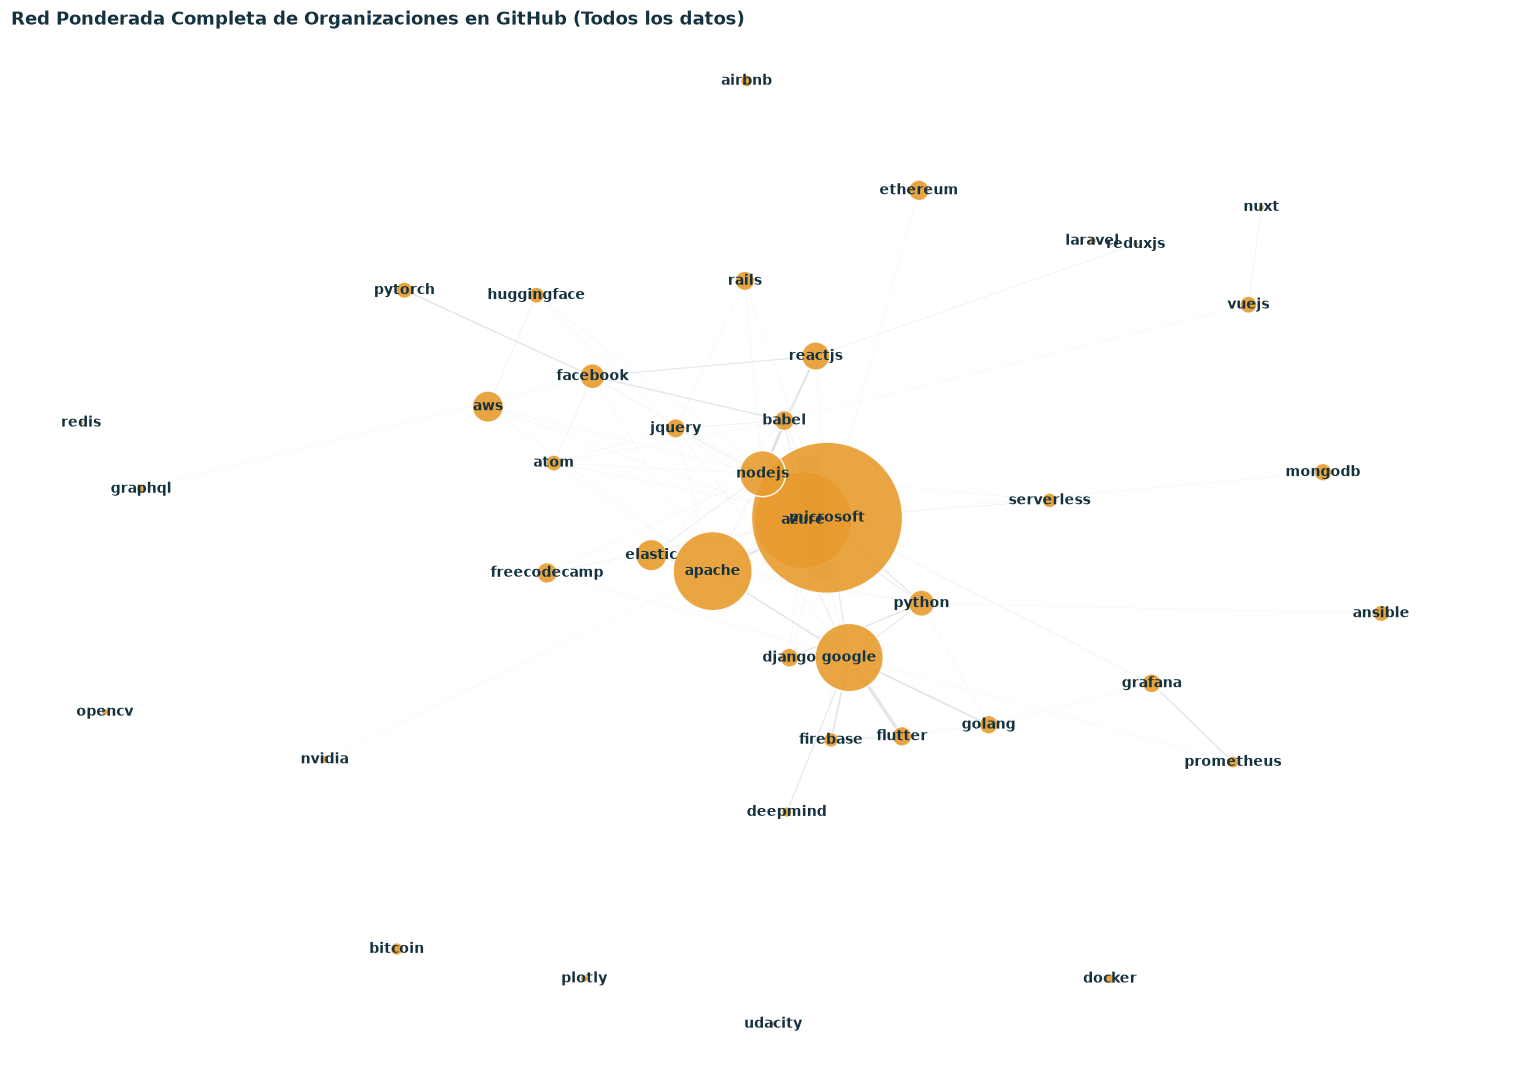


--- Resumen General del Ecosistema ---
Total de organizaciones en la red: 41
Total de conexiones (aristas) evaluadas: 84
Organizaciones involucradas con nodos puente: 33
Desarrolladores puente totales: 724


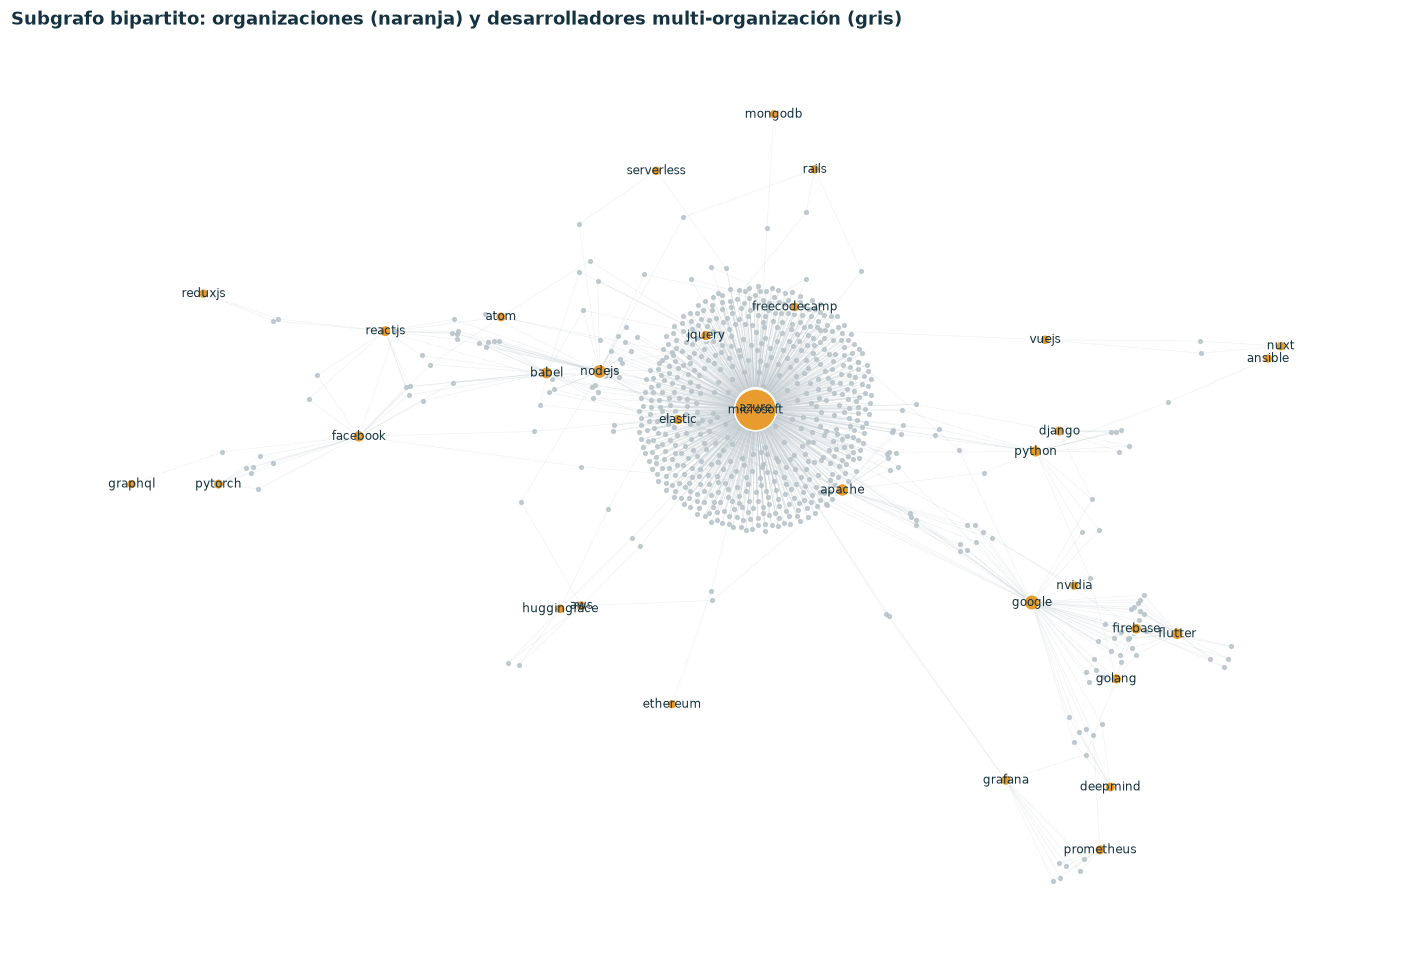

In [5]:
# Proyección ponderada sobre ORGANIZACIONES: peso = n.º de miembros compartidos
# ⚠️ NO proyecten sobre miembros: genera ~10 millones de aristas (cada org grande es un clique)
# P = bipartite.weighted_projected_graph(B, organizaciones)

import matplotlib.pyplot as plt
import networkx as nx
from networkx.algorithms import bipartite

# Colores estilo Tufte
TINTA, ACENTO, GRIS = "#14323F", "#E89B2E", "#B7C3C9"

# 1. Proyección ponderada sobre ORGANIZACIONES (usando todos los datos del grafo bipartito B)
_P = bipartite.weighted_projected_graph(B, organizaciones)
# Se reconstruye con orden determinista de nodos y aristas (los conjuntos de cadenas cambian entre ejecuciones)
P = nx.Graph()
P.add_nodes_from(sorted(_P.nodes()))
P.add_weighted_edges_from(sorted((min(u, v), max(u, v), d['weight']) for u, v, d in _P.edges(data=True)))

# 2. Identificar aristas relevantes para el reporte (Top 5)
top_aristas = sorted(P.edges(data=True), key=lambda x: x[2]['weight'], reverse=True)

print("--- Top 5 pares de organizaciones con más miembros compartidos ---")
for u, v, data in top_aristas[:5]:
    print(f"{u} y {v}: {data['weight']} miembros")

# 3. Visualización completa con TODOS los datos (sin filtrar nodos ni aristas)
plt.figure(figsize=(14, 10))
# Algoritmo de posicionamiento con mayor dispersión (k) para evitar amontonamientos
pos_P = nx.spring_layout(P, k=0.7, seed=SEMILLA)

# Tamaños proporcionales a las conexiones totales y grosores proporcionales al peso
tamaños = [B.degree(n) * 2.5 for n in P.nodes()]
grosores = [data['weight'] * 0.15 for _, _, data in P.edges(data=True)]

# Dibujar todos los nodos y todas las aristas de la red completa
nx.draw_networkx_nodes(P, pos_P, node_size=tamaños, node_color=ACENTO, alpha=0.9, edgecolors="white")
nx.draw_networkx_edges(P, pos_P, width=grosores, edge_color=GRIS, alpha=0.4)

# Etiquetas para TODAS las organizaciones de la red
nx.draw_networkx_labels(P, pos_P, font_size=9, font_color=TINTA, font_weight="bold")

plt.title("Red Ponderada Completa de Organizaciones en GitHub (Todos los datos)", 
          loc="left", fontweight="bold", color=TINTA, fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.show()

# 4. Resumen general del subgrafo completo de nodos puente
miembros_multi = [n for n in miembros if B.degree(n) > 1]
orgs_conectadas = set()
for m in miembros_multi:
    orgs_conectadas.update(B.neighbors(m))
    
sub_B = B.subgraph(miembros_multi + list(orgs_conectadas))
print(f"\n--- Resumen General del Ecosistema ---")
print(f"Total de organizaciones en la red: {P.number_of_nodes()}")
print(f"Total de conexiones (aristas) evaluadas: {P.number_of_edges()}")
print(f"Organizaciones involucradas con nodos puente: {len(orgs_conectadas)}")
print(f"Desarrolladores puente totales: {len(miembros_multi)}")


# 5. Subgrafo bipartito de los miembros multi-organización (organizaciones en ACENTO, miembros en GRIS)
set_orgs = set(organizaciones)
nodos_orgs_sub = [n for n in sub_B.nodes() if n in set_orgs]
nodos_miembros_sub = [n for n in sub_B.nodes() if n not in set_orgs]
plt.figure(figsize=(13, 9))
pos_sub = nx.spring_layout(sub_B, k=0.12, seed=SEMILLA, iterations=100)
nx.draw_networkx_edges(sub_B, pos_sub, edge_color=GRIS, alpha=0.25, width=0.4)
nx.draw_networkx_nodes(sub_B, pos_sub, nodelist=nodos_miembros_sub, node_size=6, node_color=GRIS, alpha=0.8)
nx.draw_networkx_nodes(sub_B, pos_sub, nodelist=nodos_orgs_sub,
                       node_size=[40 + sub_B.degree(n) * 1.2 for n in nodos_orgs_sub],
                       node_color=ACENTO, edgecolors="white")
nx.draw_networkx_labels(sub_B, pos_sub, labels={n: n for n in nodos_orgs_sub}, font_size=8, font_color=TINTA)
plt.title("Subgrafo bipartito: organizaciones (naranja) y desarrolladores multi-organización (gris)",
          loc="left", fontweight="bold", color=TINTA, fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.show()


**Conclusión de negocio:** La proyección tiene 41 organizaciones y 84 aristas. El par con más miembros compartidos es azure–microsoft (555), muy por encima del resto: flutter–google (15), microsoft–nodejs (15), apache–microsoft (10) y babel–nodejs (10). Esa diferencia importa: 545 de los 724 desarrolladores puente pertenecen únicamente a azure y microsoft (fase 8), de modo que la mayor parte del "puenteo" es una relación casi interna entre dos marcas del mismo grupo. Los puentes entre ecosistemas distintos son pocos y de peso bajo (10 a 15 miembros). El subgrafo bipartito muestra que 33 de las 41 organizaciones están conectadas por al menos un desarrollador puente; las 8 restantes quedan fuera.

<a id="fase-3"></a>
## Fase 3: Centralidades

Paso 3. Grado, cercanía, intermediación, vector propio y **PageRank** en la proyección (usen el peso con criterio: en cercanía e intermediación el peso es *distancia*, así que hay que invertirlo). Comparen los rankings (correlación de Spearman) y expliquen qué organización es más central según cada medida y por qué difieren; ¿qué aporta PageRank frente al vector propio? **Pista:** la proyección no es conexa, así que el vector propio se calcula sobre la **componente gigante**. Si el vector propio ponderado no converge, revisen la distribución de pesos (una sola arista puede dominar), prueben `eigenvector_centrality_numpy` o pesos en escala logarítmica, y discutan qué versión responde mejor la pregunta de negocio.

> **Pregunta de la guía:** Top-3 por cada centralidad (incluido PageRank) y correlación de Spearman. ¿Por qué difieren los rankings?

**Qué analizamos:** Calculamos el Top-3 de organizaciones para cada métrica estructural de centralidad (Grado, Cercanía, Intermediación, Vector Propio y PageRank) aplicando la transformación de distancia inversa ($1/\text{peso}$) en las métricas basadas en caminos. Asimismo, evaluamos la relación entre las jerarquías institucionales mediante una matriz de correlación de Spearman sobre la componente gigante de la proyección.

In [6]:
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import spearmanr

# 1. Distancia = 1 / peso. Se guarda en P (los algoritmos de caminos de las fases 4, 6 y 9 la leen de P)
#    y en una copia P_dist. Antes solo existía en la copia y las fases 4 y 9 corrían sin pesos.
for u, v, data in P.edges(data=True):
    data['distancia'] = 1.0 / data['weight']
P_dist = P.copy()

# 2. Centralidades
deg_cent = nx.degree_centrality(P)
clo_cent = nx.closeness_centrality(P_dist, distance='distancia')
bet_cent = nx.betweenness_centrality(P_dist, weight='distancia', normalized=True)
pagerank = nx.pagerank(P, weight='weight')

# Vector propio sobre la componente gigante (la proyección no es conexa)
cc_nodos = max(nx.connected_components(P), key=len)
P_gigante = P.subgraph(cc_nodos).copy()
try:
    eig_cent = nx.eigenvector_centrality(P_gigante, weight='weight', max_iter=1000)
    metodo_eig = "iterativo"
except Exception:
    eig_cent = nx.eigenvector_centrality_numpy(P_gigante, weight='weight')
    metodo_eig = "numpy"

# Variante con pesos en escala logarítmica: evita que la arista Azure-microsoft (555) domine
for u, v, data in P_gigante.edges(data=True):
    data['peso_log'] = np.log1p(data['weight'])
eig_log = nx.eigenvector_centrality_numpy(P_gigante, weight='peso_log')

# 3. Tabla sobre la componente gigante (donde las cinco medidas están definidas)
df_cent = pd.DataFrame({
    'Grado': pd.Series(deg_cent), 'Cercanía': pd.Series(clo_cent),
    'Intermediación': pd.Series(bet_cent), 'Vector Propio': pd.Series(eig_cent),
    'PageRank': pd.Series(pagerank),
}).loc[list(cc_nodos)]
df_cent['Vector Propio (log)'] = pd.Series(eig_log)

print(f"Componente gigante: {len(cc_nodos)} de {P.number_of_nodes()} organizaciones | vector propio: {metodo_eig}")
print("--- Top 3 por medida (componente gigante) ---")
for col in df_cent.columns:
    print(f"\n{col}:")
    for org, val in df_cent[col].nlargest(3).items():
        print(f"  - {org}: {val:.4f}")

# 4. Correlación de Spearman entre rankings, sin los nodos aislados (sin fillna(0))
print("\n--- Correlación de Spearman (componente gigante) ---")
cols = ['Grado', 'Cercanía', 'Intermediación', 'Vector Propio', 'PageRank']
rho, _ = spearmanr(df_cent[cols])
df_corr = pd.DataFrame(rho, index=cols, columns=cols)
print(df_corr.round(3))

rho_e, _ = spearmanr(df_cent['Vector Propio'], df_cent['Vector Propio (log)'])
print(f"\nSpearman vector propio crudo vs. logarítmico: {rho_e:.3f}")
print("Vector propio crudo: proporción azure+microsoft =",
      round((df_cent.loc[['azure', 'microsoft'], 'Vector Propio'] ** 2).sum() / (df_cent['Vector Propio'] ** 2).sum(), 4))
print("Vector propio (log): proporción azure+microsoft =",
      round((df_cent.loc[['azure', 'microsoft'], 'Vector Propio (log)'] ** 2).sum() / (df_cent['Vector Propio (log)'] ** 2).sum(), 4))


Componente gigante: 33 de 41 organizaciones | vector propio: numpy
--- Top 3 por medida (componente gigante) ---

Grado:
  - microsoft: 0.4750
  - nodejs: 0.3500
  - google: 0.3250

Cercanía:
  - microsoft: 1.2425
  - azure: 1.2396
  - nodejs: 1.2199

Intermediación:
  - microsoft: 0.4011
  - nodejs: 0.2895
  - babel: 0.1987

Vector Propio:
  - microsoft: 0.7069
  - azure: 0.7065
  - nodejs: 0.0232

PageRank:
  - microsoft: 0.2266
  - azure: 0.2000
  - google: 0.0653

Vector Propio (log):
  - microsoft: 0.5191
  - azure: 0.4289
  - nodejs: 0.3548

--- Correlación de Spearman (componente gigante) ---
                Grado  Cercanía  Intermediación  Vector Propio  PageRank
Grado           1.000     0.808           0.715          0.874     0.788
Cercanía        0.808     1.000           0.645          0.735     0.846
Intermediación  0.715     0.645           1.000          0.637     0.791
Vector Propio   0.874     0.735           0.637          1.000     0.594
PageRank        0.788     0.

**Conclusión de negocio:** Sobre la componente gigante (33 organizaciones), microsoft es primera en grado (0.4750; nodejs 0.3500 y google 0.3250), cercanía (1.2425, con azure en 1.2396), intermediación (0.4011; nodejs 0.2895 y babel 0.1987), vector propio (0.7069, con azure en 0.7065) y PageRank (0.2266; azure 0.2000 y google 0.0653). El vector propio crudo concentra el 99.9 % de su masa en azure y microsoft por la arista de 555 miembros; con pesos `log1p` baja al 45 % y aparecen nodejs (0.3548) y otras organizaciones (Spearman entre ambas versiones: 0.936), por lo que la versión logarítmica responde mejor a la pregunta de negocio. La correlación de Spearman, calculada solo en la gigante (los 8 nodos aislados recibirían 0 y distorsionarían los rankings), va de 0.594 (vector propio–PageRank) a 0.874 (grado–vector propio). La intermediación es la medida que más se separa de las demás (0.637–0.791): mide control de rutas entre grupos, no volumen de vecinos. PageRank reparte la influencia entre los vecinos de cada nodo (con amortiguación), mientras que el vector propio queda dominado por la arista más pesada.

<a id="fase-4"></a>
## Fase 4: Componentes conectados y propiedades de la red

Paso 3 (parte b). Componentes conectados (¿qué organizaciones quedan aisladas?), distribución de grado del bipartito, coeficiente de clustering, diámetro y longitud media de caminos de la componente gigante. Interpreten qué dicen sobre el ecosistema.

> **Pregunta de la guía:** Componentes, organizaciones aisladas, clustering, diámetro y longitud media. ¿Qué dicen del ecosistema?

**Qué analizamos:** Evaluamos la estructura global de conectividad de la red de organizaciones proyectada identificando componentes conexos y posibles organizaciones aisladas. Asimismo, calculamos métricas topológicas de la componente gigante —como el diámetro, la longitud media de caminos ponderados y el coeficiente de agrupamiento— para medir la cohesión, la eficiencia de comunicación y la tendencia a formar clústeres en el ecosistema.

Número de componentes conectados en la red de organizaciones: 9
Organizaciones aisladas (8): ['airbnb', 'bitcoin', 'docker', 'laravel', 'opencv', 'plotly', 'redis', 'udacity']

--- Componente gigante: 33 de 41 organizaciones ---
Ponderado (distancia=1/peso): diámetro = 2.8667 | longitud media = 1.1763
En saltos (sin pesos):        diámetro = 5 | longitud media = 2.3011

Clustering ponderado promedio (toda P): 0.0017
Clustering sin pesos promedio (toda P): 0.2809
Transitividad (sin pesos):              0.3761

--- Grado en el bipartito ---
Miembros: grado 1 = 8154 (91.8%), grado >= 2 = 724, máximo = 3
Organizaciones: mediana = 51, máximo = 3916 (microsoft)


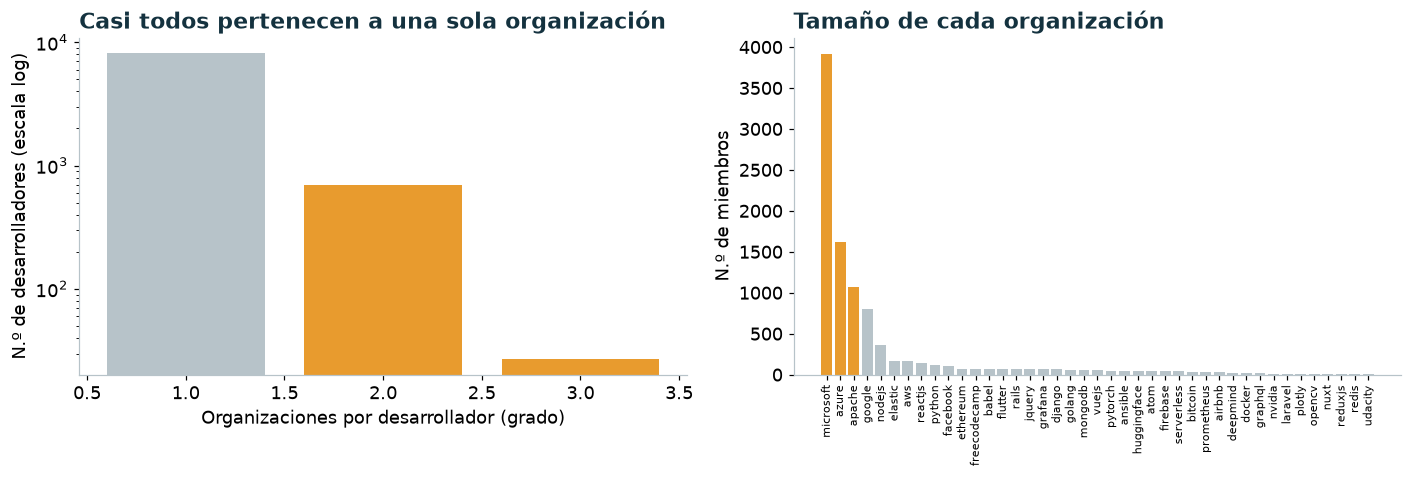

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx

# 1. Componentes conectados en la proyección de organizaciones
componentes = list(nx.connected_components(P))
print(f"Número de componentes conectados en la red de organizaciones: {len(componentes)}")
aisladas = sorted(next(iter(c)) for c in componentes if len(c) == 1)
print(f"Organizaciones aisladas ({len(aisladas)}): {aisladas if aisladas else 'Ninguna'}")

# 2. Componente gigante
cc_gigante = max(componentes, key=len)
G_gigante = P.subgraph(cc_gigante).copy()
print(f"\n--- Componente gigante: {G_gigante.number_of_nodes()} de {P.number_of_nodes()} organizaciones ---")

# 3. Propiedades de caminos: con distancia = 1/peso (P ya la guarda) y en saltos (sin pesos)
diam_w = nx.diameter(G_gigante, weight='distancia')
long_w = nx.average_shortest_path_length(G_gigante, weight='distancia')
diam_h = nx.diameter(G_gigante)
long_h = nx.average_shortest_path_length(G_gigante)
print(f"Ponderado (distancia=1/peso): diámetro = {diam_w:.4f} | longitud media = {long_w:.4f}")
print(f"En saltos (sin pesos):        diámetro = {diam_h} | longitud media = {long_h:.4f}")

# 4. Agrupamiento
print(f"\nClustering ponderado promedio (toda P): {nx.average_clustering(P, weight='weight'):.4f}")
print(f"Clustering sin pesos promedio (toda P): {nx.average_clustering(P):.4f}")
print(f"Transitividad (sin pesos):              {nx.transitivity(P):.4f}")

# 5. Distribución de grado del grafo bipartito B
grados_miembros = np.array([B.degree(n) for n in miembros])
grados_orgs = {o: B.degree(o) for o in organizaciones}
print("\n--- Grado en el bipartito ---")
print(f"Miembros: grado 1 = {(grados_miembros == 1).sum()} ({(grados_miembros == 1).mean():.1%}), "
      f"grado >= 2 = {(grados_miembros >= 2).sum()}, máximo = {grados_miembros.max()}")
print(f"Organizaciones: mediana = {np.median(list(grados_orgs.values())):.0f}, "
      f"máximo = {max(grados_orgs.values())} ({max(grados_orgs, key=grados_orgs.get)})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
valores, cuentas = np.unique(grados_miembros, return_counts=True)
ax[0].bar(valores, cuentas, color=GRIS)
ax[0].bar(valores[valores >= 2], cuentas[valores >= 2], color=ACENTO)
ax[0].set_yscale('log')
ax[0].set_xlabel("Organizaciones por desarrollador (grado)")
ax[0].set_ylabel("N.º de desarrolladores (escala log)")
ax[0].set_title("Casi todos pertenecen a una sola organización")
orden = sorted(grados_orgs.items(), key=lambda x: x[1], reverse=True)
ax[1].bar(range(len(orden)), [g for _, g in orden], color=GRIS)
ax[1].bar(range(3), [g for _, g in orden[:3]], color=ACENTO)
ax[1].set_xticks(range(len(orden)))
ax[1].set_xticklabels([o for o, _ in orden], rotation=90, fontsize=7)
ax[1].set_ylabel("N.º de miembros")
ax[1].set_title("Tamaño de cada organización")
plt.tight_layout()
plt.show()


**Conclusión de negocio:** La proyección tiene 9 componentes: una gigante con 33 organizaciones y 8 aisladas (airbnb, bitcoin, docker, laravel, opencv, plotly, redis, udacity), que no comparten ningún desarrollador con el resto. En la gigante, con distancia = 1/peso, el diámetro es 2.87 y la longitud media 1.18; en saltos (sin pesos) son 5 y 2.30. Es decir, la red es pequeña y cualquier organización alcanza a otra en pocos pasos; los pesos hacen que las rutas por pares con muchos miembros compartidos sean muy cortas. El agrupamiento ponderado es 0.0017, pero ese valor está deprimido por la escala de los pesos (555 frente a 1); sin pesos el agrupamiento medio es 0.281 y la transitividad 0.376, es decir, hay cierta cohesión local en triángulos. En el bipartito, el 91.8 % de los desarrolladores pertenece a una sola organización (máximo 3), y microsoft concentra 3 916 miembros frente a una mediana de 51 por organización.

<a id="fase-5"></a>
## Fase 5: Resiliencia y robustez

Paso 3 (parte c). Simulen la eliminación progresiva de nodos: **aleatoria** frente a **dirigida** (por grado y por intermediación). Grafiquen el tamaño relativo de la componente gigante frente a la fracción eliminada. Identifiquen los **puntos de articulación** de la proyección (`nx.articulation_points`): ¿qué organizaciones desconectan la red por sí solas? ¿Qué nodos sostienen la red? Esta fase alimenta el desafío 1.

> **Pregunta de la guía:** ¿Con qué fracción eliminada se rompe la componente gigante en el ataque dirigido vs. el aleatorio? ¿Cuáles son los puntos de articulación?

**Qué analizamos:** Simulamos la resiliencia y robustez estructural de la red mediante la eliminación progresiva de nodos bajo dos escenarios: fallos aleatorios y ataques dirigidos (basados en grado e intermediación). Graficamos la reducción del tamaño relativo de la componente gigante frente a la fracción de nodos removidos e identificamos los puntos de articulación institucionales críticos que sostienen la conectividad del ecosistema.

Puntos de articulación (8): ['apache', 'babel', 'facebook', 'google', 'microsoft', 'python', 'reactjs', 'vuejs']

Efecto de retirar cada punto de articulación (la gigante original tiene 33 organizaciones):
organización  piezas  mayor pieza  nodos desconectados de la mayor    tamaños
       babel       2           30                                2    [30, 2]
    facebook       3           30                                2 [30, 1, 1]
   microsoft       3           30                                2 [30, 1, 1]
      apache       2           31                                1    [31, 1]
      google       2           31                                1    [31, 1]
      python       2           31                                1    [31, 1]
     reactjs       2           31                                1    [31, 1]
       vuejs       2           31                                1    [31, 1]

Gigante inicial: 0.805 del total
Aleatorio (media 30)       -> gigante < 50% del total al e

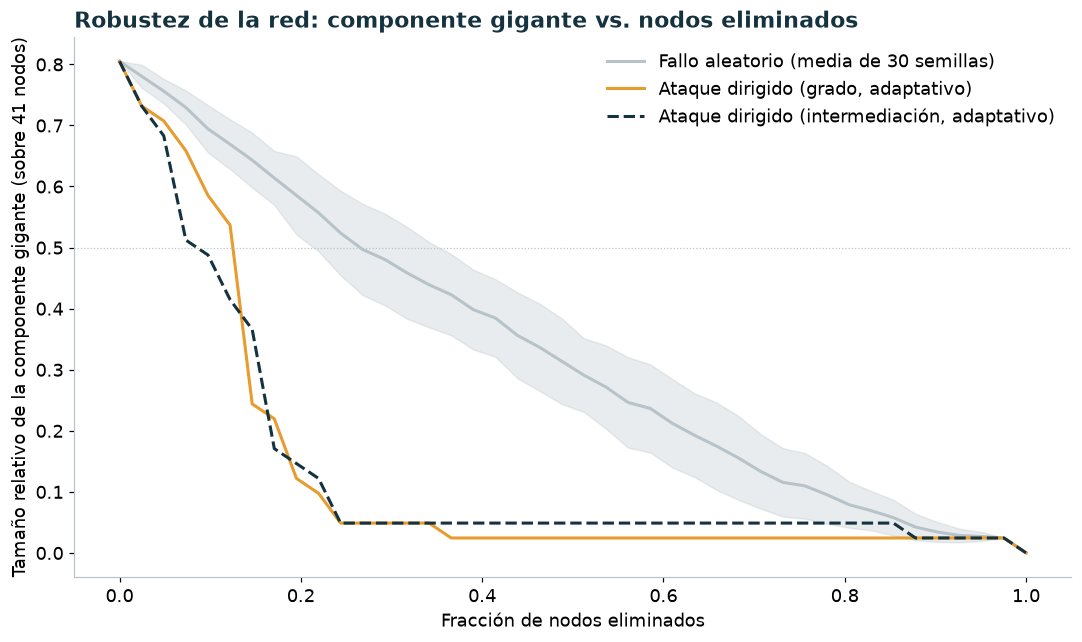

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# 1. Puntos de articulación de la proyección y tamaño de los fragmentos que dejan al salir
puntos_articulacion = sorted(nx.articulation_points(P))
print(f"Puntos de articulación ({len(puntos_articulacion)}): {puntos_articulacion}")

cc_gig = max(nx.connected_components(P), key=len)
filas_ap = []
for ap in puntos_articulacion:
    H = P.copy()
    H.remove_node(ap)
    # solo los nodos que pertenecían a la componente gigante original
    piezas = sorted((len(c & cc_gig) for c in nx.connected_components(H) if c & cc_gig), reverse=True)
    filas_ap.append({"organización": ap, "piezas": len(piezas), "mayor pieza": piezas[0],
                     "nodos desconectados de la mayor": sum(piezas[1:]), "tamaños": piezas})
import pandas as pd
df_ap = pd.DataFrame(filas_ap).sort_values("nodos desconectados de la mayor", ascending=False)
print("\nEfecto de retirar cada punto de articulación (la gigante original tiene "
      f"{len(cc_gig)} organizaciones):")
print(df_ap.to_string(index=False))

# 2. Simulación: fallo aleatorio (promedio de 30 semillas) vs. ataque dirigido ADAPTATIVO
#    (tras cada eliminación se recalcula grado o intermediación sobre la red restante).
#    Las métricas de ataque usan la topología (sin pesos). El eje Y es relativo a los 41 nodos originales.
def tam_gigante(H):
    return max((len(c) for c in nx.connected_components(H)), default=0)

def curva_aleatoria(G, semilla):
    rng = np.random.default_rng(semilla)
    nodos = list(G.nodes())
    rng.shuffle(nodos)
    H, n = G.copy(), G.number_of_nodes()
    ys = [tam_gigante(H) / n]
    for x in nodos:
        H.remove_node(x)
        ys.append(tam_gigante(H) / n)
    return np.array(ys)

def curva_dirigida(G, medida):
    H, n = G.copy(), G.number_of_nodes()
    ys = [tam_gigante(H) / n]
    while H.number_of_nodes() > 0:
        puntaje = dict(H.degree()) if medida == 'grado' else nx.betweenness_centrality(H)
        objetivo = max(sorted(puntaje), key=lambda k: puntaje[k])   # desempate alfabético (determinista)
        H.remove_node(objetivo)
        ys.append(tam_gigante(H) / n)
    return np.array(ys)

n_total = P.number_of_nodes()
x = np.arange(n_total + 1) / n_total
todas = np.array([curva_aleatoria(P, s) for s in range(30)])
y_rand, y_rand_sd = todas.mean(axis=0), todas.std(axis=0)
y_deg = curva_dirigida(P, 'grado')
y_bet = curva_dirigida(P, 'intermediacion')

def fraccion_umbral(y, umbral=0.5):
    """Primera fracción eliminada en que la gigante cae por debajo de `umbral` del total original."""
    idx = np.argmax(y < umbral)
    return x[idx] if (y < umbral).any() else float('nan')

print(f"\nGigante inicial: {y_rand[0]:.3f} del total")
for nombre, y in [("Aleatorio (media 30)", y_rand), ("Dirigido grado", y_deg), ("Dirigido intermediación", y_bet)]:
    print(f"{nombre:26s} -> gigante < 50% del total al eliminar {fraccion_umbral(y):.1%} de los nodos "
          f"({int(round(fraccion_umbral(y) * n_total))} de {n_total})")
print(f"Gigante tras eliminar 10% de nodos (4): aleatorio={y_rand[4]:.3f}, grado={y_deg[4]:.3f}, intermediación={y_bet[4]:.3f}")

# 3. Gráfico
plt.figure(figsize=(10, 6))
plt.plot(x, y_rand, label='Fallo aleatorio (media de 30 semillas)', color=GRIS, linewidth=2)
plt.fill_between(x, y_rand - y_rand_sd, y_rand + y_rand_sd, color=GRIS, alpha=0.3)
plt.plot(x, y_deg, label='Ataque dirigido (grado, adaptativo)', color=ACENTO, linewidth=2)
plt.plot(x, y_bet, label='Ataque dirigido (intermediación, adaptativo)', color=TINTA, linewidth=2, linestyle='--')
plt.axhline(0.5, color=GRIS, linewidth=0.8, linestyle=':')
plt.title("Robustez de la red: componente gigante vs. nodos eliminados", loc="left", fontweight="bold", color=TINTA)
plt.xlabel("Fracción de nodos eliminados")
plt.ylabel("Tamaño relativo de la componente gigante (sobre 41 nodos)")
plt.legend()
plt.tight_layout()
plt.show()


**Conclusión de negocio:** Hay 8 puntos de articulación (`nx.articulation_points`: apache, babel, facebook, google, microsoft, python, reactjs, vuejs). Retirar cualquiera de ellos no destruye la red: deja una pieza de 30 o 31 organizaciones y separa solo 1 o 2 organizaciones (babel deja una pieza de 2; facebook y microsoft dejan dos organizaciones sueltas). Es una fragilidad local, no un colapso. En la simulación (el eje mide la gigante sobre las 41 organizaciones; parte de 0.805), la componente gigante cae por debajo del 50 % al eliminar el 26.8 % de los nodos (11 de 41) con fallo aleatorio (media de 30 semillas), el 14.6 % (6 de 41) con ataque dirigido por grado y el 9.8 % (4 de 41) con ataque por intermediación, ambos adaptativos. Con 4 nodos eliminados (10 %) la gigante vale 0.694 (aleatorio), 0.585 (grado) y 0.488 (intermediación). La red tolera mejor los fallos aleatorios que los ataques dirigidos, y la intermediación identifica los nodos más críticos.

<a id="fase-6"></a>
## Fase 6: Caminos: BFS, DFS, Dijkstra y Floyd-Warshall

Paso 4. Recorran la red con BFS y DFS desde una organización y comparen el orden de visita. Calculen el camino mínimo ponderado entre dos organizaciones con **Dijkstra** y todos los caminos mínimos con **Floyd-Warshall** sobre la proyección de organizaciones (distancia = 1/peso). Expliquen por qué Floyd-Warshall no conviene en el grafo completo (complejidad O(n³)) y cuándo Dijkstra es la alternativa.

> **Pregunta de la guía:** Orden de visita BFS vs. DFS, camino de Dijkstra entre dos organizaciones y por qué Floyd-Warshall no escala (O(n³)).

**Qué analizamos:** Realizamos recorridos estructurales en la red mediante BFS y DFS desde una organización de referencia para comparar su orden de visita. Calculamos el camino mínimo ponderado entre dos organizaciones clave utilizando el algoritmo de Dijkstra (con distancia inversa) y analizamos la limitación de escalabilidad de Floyd-Warshall sobre la matriz completa de distancias debido a su complejidad cúbica ($O(n^3)$).

In [9]:
import time
import numpy as np
import networkx as nx

origen = 'microsoft' if 'microsoft' in P.nodes() else list(P.nodes())[0]
destino = 'google' if 'google' in P.nodes() else list(P.nodes())[1]

# 1. Recorridos BFS y DFS (el orden depende del orden de inserción de los vecinos en NetworkX)
orden_bfs = list(nx.bfs_tree(P, source=origen).nodes())
orden_dfs = list(nx.dfs_tree(P, source=origen).nodes())
print(f"--- Recorridos desde '{origen}' (alcanza {len(orden_bfs)} de {P.number_of_nodes()} organizaciones) ---")
print(f"Orden BFS (primeros 8): {orden_bfs[:8]}")
print(f"Orden DFS (primeros 8): {orden_dfs[:8]}")
print(f"Vecinos directos de {origen}: {P.degree(origen)} | BFS: los primeros {P.degree(origen)} visitados tras el origen son sus vecinos")

# 2. Dijkstra entre dos organizaciones (distancia = 1/peso)
camino = nx.dijkstra_path(P_dist, origen, destino, weight='distancia')
dist_dij = nx.dijkstra_path_length(P_dist, origen, destino, weight='distancia')
print(f"\n--- Dijkstra '{origen}' -> '{destino}' ---")
print(f"Ruta: {' -> '.join(camino)} | distancia = {dist_dij:.4f} (peso directo = {P[origen][destino]['weight']})")

# 3. Floyd-Warshall (todos los pares) y verificación contra Dijkstra desde cada origen
t0 = time.perf_counter()
fw = nx.floyd_warshall(P_dist, weight='distancia')
t_fw = time.perf_counter() - t0

t0 = time.perf_counter()
dj = {n: nx.single_source_dijkstra_path_length(P_dist, n, weight='distancia') for n in P_dist.nodes()}
t_dj = time.perf_counter() - t0

max_dif, pares_inf, pares_fin = 0.0, 0, 0
for u in P_dist.nodes():
    for v in P_dist.nodes():
        d_fw = fw[u][v]
        d_dj = dj[u].get(v, float('inf'))
        if np.isinf(d_fw) or np.isinf(d_dj):
            assert np.isinf(d_fw) and np.isinf(d_dj)   # ambos deben coincidir en 'sin camino'
            pares_inf += 1
        else:
            pares_fin += 1
            max_dif = max(max_dif, abs(d_fw - d_dj))

print(f"\n--- Floyd-Warshall vs. {P_dist.number_of_nodes()} ejecuciones de Dijkstra ---")
print(f"Distancia {origen}->{destino}: FW = {fw[origen][destino]:.4f} | Dijkstra = {dist_dij:.4f}")
print(f"Pares con camino: {pares_fin} | pares sin camino (inf, otras componentes): {pares_inf}")
print(f"Diferencia máxima FW vs. Dijkstra: {max_dif:.2e}")
print(f"Tiempo FW: {t_fw:.4f}s | Tiempo 41 Dijkstra: {t_dj:.4f}s")

# 4. Escalabilidad
n_nodos = P.number_of_nodes()
print(f"\n--- Escalabilidad ---")
print(f"n = {n_nodos}: n^3 = {n_nodos**3:,} operaciones | n = 10,000: {10_000**3:,} | n = 1,000,000: {1_000_000**3:.0e}")
print("Floyd-Warshall es O(n^3) en tiempo y O(n^2) en memoria; Dijkstra desde un origen cuesta O(m + n log n).")


--- Recorridos desde 'microsoft' (alcanza 33 de 41 organizaciones) ---
Orden BFS (primeros 8): ['microsoft', 'apache', 'atom', 'azure', 'babel', 'django', 'elastic', 'ethereum']
Orden DFS (primeros 8): ['microsoft', 'apache', 'atom', 'babel', 'azure', 'aws', 'huggingface', 'jquery']
Vecinos directos de microsoft: 19 | BFS: los primeros 19 visitados tras el origen son sus vecinos

--- Dijkstra 'microsoft' -> 'google' ---
Ruta: microsoft -> google | distancia = 0.2000 (peso directo = 5)

--- Floyd-Warshall vs. 41 ejecuciones de Dijkstra ---
Distancia microsoft->google: FW = 0.2000 | Dijkstra = 0.2000
Pares con camino: 1097 | pares sin camino (inf, otras componentes): 584
Diferencia máxima FW vs. Dijkstra: 4.44e-16
Tiempo FW: 0.0054s | Tiempo 41 Dijkstra: 0.0022s

--- Escalabilidad ---
n = 41: n^3 = 68,921 operaciones | n = 10,000: 1,000,000,000,000 | n = 1,000,000: 1e+18
Floyd-Warshall es O(n^3) en tiempo y O(n^2) en memoria; Dijkstra desde un origen cuesta O(m + n log n).


**Conclusión de negocio:** Desde microsoft se alcanzan 33 de las 41 organizaciones. BFS visita primero a sus 19 vecinos directos (apache, atom, azure, babel, django, elastic, ethereum, ...) y avanza por capas; DFS entra en profundidad por una rama (apache, atom, babel, azure, aws, huggingface, jquery, ...). Dijkstra encuentra que microsoft y google se conectan directamente, con distancia 0.2 (peso 5). Floyd-Warshall se ejecutó sobre toda la proyección: coincide con 41 corridas de Dijkstra (diferencia máxima 4.4e-16), con 1 097 pares con camino y 584 pares sin camino (infinito, por las componentes separadas). Con 41 nodos ambos tardan milisegundos (FW ≈ 0.005 s frente a ≈ 0.002 s de las 41 corridas de Dijkstra; los tiempos varían por ejecución), pero FW es O(n³) en tiempo y O(n²) en memoria: con n = 10 000 serían 10¹² operaciones. Dijkstra, con un origen o pocos orígenes, es la alternativa cuando la red es grande y rala.

<a id="fase-7"></a>
## Fase 7: Detección de comunidades

Paso 5. Apliquen y **comparen** Girvan-Newman, Louvain, **Leiden** (`nx.community.leiden_communities`, NetworkX ≥ 3.7, con `metric="modularity"` para compararlo con Louvain) y propagación de etiquetas. Verifiquen si alguna comunidad resulta internamente desconectada. Comparen modularidad, número y tamaño de comunidades, estabilidad entre semillas y tiempo. Argumenten cuál usarían y por qué.

> **Pregunta de la guía:** Modularidad, n.º de comunidades, estabilidad y tiempo por algoritmo. ¿Cuál eligen y por qué?

**Qué analizamos:** Aplicamos y comparamos diferentes algoritmos de detección de comunidades en la red de organizaciones (Louvain, Leiden con modularidad, propagación de etiquetas y Girvan-Newman). Evaluamos la calidad de la partición mediante el índice de modularidad, el número y tamaño de las comunidades obtenidas, así como su estabilidad y tiempo de ejecución, para argumentar qué enfoque resulta más robusto para modelar la estructura modular del ecosistema.

In [10]:
import time
import numpy as np
import pandas as pd
import networkx as nx
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import community as community_louvain   # python-louvain

nodos_P = list(P.nodes())
SEMILLAS = list(range(20))

# NetworkX itera conjuntos de nodos: con nombres (str) el orden puede cambiar entre ejecuciones por la aleatorización
# del hash (PYTHONHASHSEED). Por precaución, Leiden y LPA se ejecutan sobre una copia con nodos enteros (0..40, en el
# orden alfabético de P) y semilla fija, y la variación se mide con 20 semillas (ARI/NMI frente a la semilla 42).
_a_int = {n: i for i, n in enumerate(nodos_P)}
P_int = nx.relabel_nodes(P, _a_int, copy=True)
def _a_nombres(comunidades):
    return [{nodos_P[i] for i in c} for c in comunidades]

def a_etiquetas(comunidades):
    """Lista de etiquetas alineada con nodos_P (para ARI/NMI)."""
    mapa = {n: i for i, c in enumerate(comunidades) for n in c}
    return [mapa[n] for n in nodos_P]

def Q(comunidades):
    return nx.community.modularity(P, comunidades, weight='weight')

def louvain(seed):
    part = community_louvain.best_partition(P, weight='weight', random_state=seed)
    grupos = {}
    for n, c in part.items():
        grupos.setdefault(c, set()).add(n)
    return list(grupos.values())

def leiden(seed):
    # metric="modularity" es obligatorio: por defecto NetworkX usa CPM y la comparación con Louvain no es válida
    return _a_nombres(nx.community.leiden_communities(P_int, weight='weight', seed=seed, metric="modularity"))

def lpa(seed):
    return _a_nombres(nx.community.asyn_lpa_communities(P_int, weight='weight', seed=seed))

def girvan_newman():
    # Arista más valiosa = mayor intermediación de arista con distancia 1/peso (aristas con muchos miembros = cercanas)
    def arista(G):
        eb = nx.edge_betweenness_centrality(G, weight='distancia')
        return max(sorted(eb), key=lambda e: eb[e])
    mejor, mejor_q = None, -1
    for particion in nx.community.girvan_newman(P, most_valuable_edge=arista):
        q = Q(particion)
        if q > mejor_q:
            mejor, mejor_q = [set(c) for c in particion], q
    return mejor

def desconectadas(comunidades):
    """N.º de comunidades de más de un nodo cuyo subgrafo inducido no es conexo."""
    return sum(1 for c in comunidades if len(c) > 1 and not nx.is_connected(P.subgraph(c)))

# --- Ejecución de referencia (seed = 42) con tiempos ---
resultados, ref = {}, {}
for nombre, f in [("Louvain", lambda: louvain(SEMILLA)), ("Leiden", lambda: leiden(SEMILLA)),
                  ("Label Propagation", lambda: lpa(SEMILLA)), ("Girvan-Newman", girvan_newman)]:
    t0 = time.perf_counter()
    com = f()
    t = time.perf_counter() - t0
    ref[nombre] = com
    resultados[nombre] = {"Q": Q(com), "n comunidades": len(com), "mayor": max(len(c) for c in com),
                          "singletons": sum(1 for c in com if len(c) == 1),
                          "desconectadas": desconectadas(com), "tiempo (s)": t}

# --- Estabilidad: 20 semillas (Girvan-Newman es determinista) ---
fun = {"Louvain": louvain, "Leiden": leiden, "Label Propagation": lpa}
for nombre, f in fun.items():
    qs, ns, aris, nmis = [], [], [], []
    base = a_etiquetas(ref[nombre])
    for s in SEMILLAS:
        com = f(s)
        qs.append(Q(com)); ns.append(len(com))
        et = a_etiquetas(com)
        aris.append(adjusted_rand_score(base, et)); nmis.append(normalized_mutual_info_score(base, et))
    resultados[nombre].update({"Q media±sd (20 sem.)": f"{np.mean(qs):.4f} ± {np.std(qs):.4f}",
                               "n com. media±sd": f"{np.mean(ns):.1f} ± {np.std(ns):.1f}",
                               "ARI vs seed 42": round(float(np.mean(aris)), 3),
                               "NMI vs seed 42": round(float(np.mean(nmis)), 3)})
resultados["Girvan-Newman"].update({"Q media±sd (20 sem.)": "determinista", "n com. media±sd": "determinista",
                                    "ARI vs seed 42": 1.0, "NMI vs seed 42": 1.0})

df_com = pd.DataFrame(resultados).T
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 20)
print("--- Comparación de algoritmos de comunidades (red ponderada P, 41 organizaciones) ---")
print(df_com.to_string())

# Louvain en formato {id: [nodos]} (lo usa el mini GraphRAG de la fase 9)
comunidades_louvain = {i: sorted(c) for i, c in enumerate(sorted(ref["Louvain"], key=len, reverse=True))}
comunidades_leiden = ref["Leiden"]
print("\n--- Comunidades de Louvain (seed 42) ---")
for cid, mc in comunidades_louvain.items():
    print(f"  Comunidad {cid} ({len(mc)}): {mc}")
print("\n--- Comunidades de Leiden (seed 42, modularity) ---")
for i, c in enumerate(sorted(comunidades_leiden, key=len, reverse=True)):
    print(f"  Comunidad {i} ({len(c)}): {sorted(c)}")


--- Comparación de algoritmos de comunidades (red ponderada P, 41 organizaciones) ---
                          Q n comunidades mayor singletons desconectadas tiempo (s) Q media±sd (20 sem.) n com. media±sd ARI vs seed 42 NMI vs seed 42
Louvain               0.288            11    16          8             0   0.001594      0.2886 ± 0.0005      11.0 ± 0.0          0.807          0.903
Leiden             0.288987            11    18          8             0   0.002535      0.2882 ± 0.0008      11.0 ± 0.0          0.859          0.925
Label Propagation  0.118704            12    24          8             0   0.000722      0.1120 ± 0.0520      11.9 ± 0.4          0.926          0.972
Girvan-Newman      0.081218            19    11         11             0   0.157971         determinista    determinista            1.0            1.0

--- Comunidades de Louvain (seed 42) ---
  Comunidad 0 (16): ['atom', 'aws', 'babel', 'facebook', 'freecodecamp', 'graphql', 'huggingface', 'jquery', 'nodejs'

**Conclusión de negocio:** Con `metric="modularity"` (por defecto NetworkX usa CPM y no sería comparable), Leiden y Louvain quedan prácticamente empatados: con la semilla 42, modularidad de 0.2890 (Leiden) y 0.2880 (Louvain), 11 comunidades cada uno, de las cuales 8 son organizaciones aisladas y 3 son comunidades reales (en Leiden, 18, 11 y 4 organizaciones; por ejemplo, microsoft–azure–ethereum–mongodb forman una). Propagación de etiquetas (asíncrona, con pesos) es peor: Q = 0.119 con 12 comunidades y 0.112 ± 0.052 en 20 semillas. Girvan-Newman alcanza Q = 0.081 con 19 comunidades. Ninguna comunidad resultó internamente desconectada. Tratamiento de Leiden: como NetworkX puede iterar los nodos `str` en un orden que depende del hash, Leiden y LPA se ejecutan sobre una copia con nodos enteros y semilla fija; la variación entre corridas se mide con 20 semillas. En esas 20 semillas Louvain tiene una Q media algo mayor y más estable (0.2886 ± 0.0005 frente a 0.2882 ± 0.0008 de Leiden), pero Leiden reproduce mejor la partición de referencia (ARI 0.859 y NMI 0.925 frente a 0.807 y 0.903 de Louvain); ambos dan 11.0 ± 0.0 comunidades. Usaríamos Leiden porque iguala la modularidad de Louvain, cambia menos de partición entre semillas y garantiza comunidades conectadas; Louvain es una alternativa igual de válida en esta red.

<a id="fase-8"></a>
## Fase 8: Sistema de recomendación y desafío

Construyan un recomendador **colaborativo sobre el grafo**: para un miembro, puntúen las organizaciones a las que no pertenece según su similitud con las suyas (miembros compartidos, coseno o Jaccard). **Evalúen:** oculten una membresía de cada miembro multi-organización, recomienden top-k y midan hit@k frente a una línea base de popularidad. Respondan el desafío con evidencia de todas las fases.

> **Pregunta de la guía:** hit@k del recomendador vs. popularidad y las 3 organizaciones puente del desafío.

**Qué analizamos:** Diseñamos un sistema de recomendación colaborativo basado en la estructura bipartita de la red para sugerir nuevas organizaciones a los desarrolladores con base en las afinidades de sus pares compartidos. Evaluamos la calidad de las recomendaciones mediante la métrica hit@k frente a una línea base de popularidad global, y resolvemos el desafío institucional identificando con evidencia empírica las organizaciones puente más críticas.

In [11]:
import numpy as np
import pandas as pd
import networkx as nx

# ===== 1. Matriz organización x miembro y co-ocurrencias =====
orgs = list(organizaciones)
idx_org = {o: i for i, o in enumerate(orgs)}
miembros_lista = list(miembros)
idx_mie = {m: j for j, m in enumerate(miembros_lista)}
A = np.zeros((len(orgs), len(miembros_lista)), dtype=np.int32)          # A[o, m] = 1 si m pertenece a o
for o, m in zip(df_clean['Organisation'], df_clean['member']):
    A[idx_org[o], idx_mie[m]] = 1
I = A @ A.T                    # I[o, c] = miembros compartidos entre o y c
tam = A.sum(axis=1)            # tamaño de cada organización (grado en el bipartito)
multi_cols = np.where(A.sum(axis=0) > 1)[0]
print(f"Miembros multi-organización evaluables: {len(multi_cols)}")

# ===== 2. Recomendador sin fuga =====
# Para un miembro m con la membresía oculta h: R = organizaciones que le quedan.
# Se retira la arista (m, h) ANTES de puntuar: |h| baja en 1 y m deja de contar en I[o, h] para o en R.
def puntajes(R, h):
    I2 = I[R, :].astype(float)
    I2[:, h] -= 1.0
    s = tam.astype(float).copy()
    s[h] -= 1.0
    sR = tam[R].astype(float)
    union = sR[:, None] + s[None, :] - I2
    return {
        "Co-ocurrencia": I2.sum(axis=0),
        "Jaccard": np.divide(I2, union, out=np.zeros_like(I2), where=union > 0).sum(axis=0),
        "Coseno": (I2 / np.sqrt(np.maximum(sR[:, None] * s[None, :], 1.0))).sum(axis=0),
        "Popularidad (línea base)": s,     # tamaño de la organización con la arista oculta ya retirada
    }

def top_k(puntaje, R, rng, k=5):
    sc = puntaje.copy()
    sc[R] = -np.inf                                     # nunca se recomienda una organización que ya tiene
    desempate = rng.random(len(sc))                     # empates resueltos al azar (con semilla)
    return np.lexsort((desempate, -sc))[:k]

KS = (1, 3, 5)

def evaluar(columnas, semilla):
    rng = np.random.default_rng(semilla)
    aciertos = None
    for j in columnas:
        orgs_j = np.where(A[:, j] == 1)[0]
        h = rng.choice(orgs_j)                          # membresía oculta
        R = orgs_j[orgs_j != h]
        for metodo, sc in puntajes(R, h).items():
            top = top_k(sc, R, rng)
            if aciertos is None:
                aciertos = {}
            for k in KS:
                aciertos.setdefault((metodo, k), 0)
                aciertos[(metodo, k)] += int(h in top[:k])
    return {clave: v / len(columnas) for clave, v in aciertos.items()}

def resumen(columnas, etiqueta, n_semillas=10):
    corridas = [evaluar(columnas, s) for s in range(n_semillas)]
    filas = {}
    for metodo in ["Co-ocurrencia", "Jaccard", "Coseno", "Popularidad (línea base)"]:
        filas[metodo] = {f"hit@{k}": f"{np.mean([c[(metodo, k)] for c in corridas]):.3f} ± "
                                      f"{np.std([c[(metodo, k)] for c in corridas]):.3f}" for k in KS}
    print(f"\n=== {etiqueta} (n = {len(columnas)} miembros, {n_semillas} semillas) ===")
    print(pd.DataFrame(filas).T.to_string())
    return corridas

todas = resumen(multi_cols, "Todos los miembros multi-organización")

# Robustez: se excluyen los miembros cuyas organizaciones son solo {Azure, microsoft}
solo_az_ms = {idx_org['azure'], idx_org['microsoft']}
sin_az_ms = [j for j in multi_cols if not set(np.where(A[:, j] == 1)[0]) <= solo_az_ms]
print(f"\nMiembros solo en {{azure, microsoft}}: {len(multi_cols) - len(sin_az_ms)} de {len(multi_cols)}")
sin_dominio = resumen(sin_az_ms, "Sin los miembros exclusivos de Azure+microsoft")

# ===== 3. Desafío 1: organizaciones puente con evidencia combinada =====
# Evidencia: intermediación (fase 3), punto de articulación (fase 5) y simulación de retiro de cada organización.
cc0 = max(nx.connected_components(P), key=len)
n_comp0 = nx.number_connected_components(P)
filas = []
for o in P.nodes():
    H = P.copy()
    H.remove_node(o)
    comps = sorted((len(c) for c in nx.connected_components(H)), reverse=True)
    perdidos = (len(cc0) - 1 - comps[0]) if o in cc0 else 0       # nodos que dejan de estar en la gigante
    filas.append({"organización": o, "intermediación": bet_cent[o], "articulación": o in puntos_articulacion,
                  "gigante tras retirar": comps[0], "componentes tras retirar": len(comps),
                  "orgs desconectadas de la gigante": perdidos})
df_puente = pd.DataFrame(filas)
df_puente["rango"] = (df_puente["intermediación"].rank(ascending=False) +
                      df_puente["orgs desconectadas de la gigante"].rank(ascending=False)) / 2
df_puente = df_puente.sort_values(["rango", "intermediación"], ascending=[True, False]).reset_index(drop=True)
print("\n--- Desafío 1: organizaciones puente (rango = promedio de rangos de intermediación y fragmentación) ---")
print(df_puente.head(8).round(4).to_string(index=False))

top_bridge_orgs = [(r["organización"], r["intermediación"]) for _, r in df_puente.head(3).iterrows()]
print("\nTop 3 organizaciones puente:", [o for o, _ in top_bridge_orgs])

# Desarrolladores puente (la guía admite "organizaciones o desarrolladores")
top_dev = sorted(((m, B.degree(m)) for m in miembros_lista), key=lambda x: x[1], reverse=True)[:5]
print("Desarrolladores en más organizaciones:", top_dev)


Miembros multi-organización evaluables: 724



=== Todos los miembros multi-organización (n = 724 miembros, 10 semillas) ===
                                  hit@1          hit@3          hit@5
Co-ocurrencia             0.837 ± 0.003  0.908 ± 0.004  0.929 ± 0.002
Jaccard                   0.818 ± 0.004  0.897 ± 0.005  0.930 ± 0.004
Coseno                    0.822 ± 0.004  0.893 ± 0.004  0.928 ± 0.005
Popularidad (línea base)  0.786 ± 0.004  0.815 ± 0.004  0.871 ± 0.008

Miembros solo en {azure, microsoft}: 545 de 724

=== Sin los miembros exclusivos de Azure+microsoft (n = 179 miembros, 10 semillas) ===
                                  hit@1          hit@3          hit@5
Co-ocurrencia             0.337 ± 0.014  0.625 ± 0.016  0.713 ± 0.009
Jaccard                   0.264 ± 0.015  0.582 ± 0.018  0.709 ± 0.012
Coseno                    0.277 ± 0.017  0.564 ± 0.020  0.703 ± 0.017
Popularidad (línea base)  0.131 ± 0.026  0.249 ± 0.017  0.478 ± 0.018

--- Desafío 1: organizaciones puente (rango = promedio de rangos de intermediación 

**Conclusión de negocio:** El recomendador se evaluó ocultando una membresía por cada uno de los 724 desarrolladores multi-organización y retirando esa arista antes de puntuar (sin fuga), tanto para las similitudes como para la popularidad, con 10 semillas. La co-ocurrencia logra hit@1/3/5 de 0.837 / 0.908 / 0.929 frente a 0.786 / 0.815 / 0.871 de la línea base de popularidad; Jaccard y coseno quedan en rangos similares. Esa ventaja está inflada: 545 de los 724 desarrolladores solo pertenecen a azure y microsoft, por lo que casi cualquier método acierta. Al excluirlos (179 desarrolladores), la co-ocurrencia obtiene 0.337 / 0.625 / 0.713 frente a 0.131 / 0.249 / 0.478 de popularidad: el recomendador sí supera claramente a la popularidad, pero con un hit@3 de 0.625, no de 0.9. Para el desafío 1 se combinó intermediación, punto de articulación y retiro simulado de cada organización: las 3 organizaciones puente son microsoft (intermediación 0.4011), babel (0.1987) y facebook (0.1141). Las tres son puntos de articulación y su salida deja desconectadas 2 organizaciones de la gigante. nodejs tiene la segunda intermediación (0.2895), pero no es un punto de articulación; google tiene mayor intermediación (0.1513) que facebook, pero su salida aísla solo 1 organización. Los desarrolladores con más membresías pertenecen a solo 3 organizaciones.

### Control: efecto de NO retirar la arista oculta

El recomendador retira la membresía oculta antes de puntuar. Este control repite la evaluación con las mismas semillas y los mismos miembros, pero **sin** esos dos retiros (`-= 1.0`), para medir cuánto inflaría el hit@k una fuga de información.

In [12]:
# ===== Control: recomendador CON fuga vs SIN fuga (misma evaluación, mismas semillas y miembros) =====
# Variante con fuga: idéntica a `puntajes`, pero sin retirar la arista oculta (m, h) antes de puntuar.
def puntajes_con_fuga(R, h):
    I2 = I[R, :].astype(float)            # aquí NO se hace I2[:, h] -= 1.0
    s = tam.astype(float).copy()          # aquí NO se hace s[h] -= 1.0
    sR = tam[R].astype(float)
    union = sR[:, None] + s[None, :] - I2
    return {
        "Co-ocurrencia": I2.sum(axis=0),
        "Jaccard": np.divide(I2, union, out=np.zeros_like(I2), where=union > 0).sum(axis=0),
        "Coseno": (I2 / np.sqrt(np.maximum(sR[:, None] * s[None, :], 1.0))).sum(axis=0),
        "Popularidad (línea base)": s,
    }

def corridas_de(variante, columnas, n=10):
    """Reutiliza `evaluar` cambiando temporalmente la función de puntajes y restaurándola al terminar."""
    global puntajes
    original = puntajes
    puntajes = variante
    try:
        return [evaluar(columnas, s) for s in range(n)]
    finally:
        puntajes = original

metodos = ["Co-ocurrencia", "Jaccard", "Coseno", "Popularidad (línea base)"]
for etiqueta, cols in [("Todos los miembros multi-organización", multi_cols),
                       ("Sin los miembros exclusivos de Azure+microsoft", sin_az_ms)]:
    limpio = corridas_de(puntajes, cols)
    con_fuga = corridas_de(puntajes_con_fuga, cols)
    filas = []
    for metodo in metodos:
        for k in KS:
            a = np.mean([c[(metodo, k)] for c in limpio])
            b = np.mean([c[(metodo, k)] for c in con_fuga])
            filas.append({"método": metodo, "k": f"hit@{k}", "sin fuga": round(a, 3),
                          "con fuga": round(b, 3), "diferencia (pts)": round((b - a) * 100, 1)})
    print()
    print(f"=== Control de fuga: {etiqueta} (n = {len(cols)}, 10 semillas) ===")
    print(pd.DataFrame(filas).to_string(index=False))



=== Control de fuga: Todos los miembros multi-organización (n = 724, 10 semillas) ===
                  método     k  sin fuga  con fuga  diferencia (pts)
           Co-ocurrencia hit@1     0.837     0.854               1.7
           Co-ocurrencia hit@3     0.908     0.933               2.6
           Co-ocurrencia hit@5     0.929     0.960               3.1
                 Jaccard hit@1     0.818     0.839               2.1
                 Jaccard hit@3     0.897     0.926               2.9
                 Jaccard hit@5     0.930     0.958               2.8
                  Coseno hit@1     0.822     0.843               2.1
                  Coseno hit@3     0.893     0.920               2.7
                  Coseno hit@5     0.928     0.959               3.0
Popularidad (línea base) hit@1     0.786     0.786               0.0
Popularidad (línea base) hit@3     0.815     0.815               0.0
Popularidad (línea base) hit@5     0.871     0.874               0.3



=== Control de fuga: Sin los miembros exclusivos de Azure+microsoft (n = 179, 10 semillas) ===
                  método     k  sin fuga  con fuga  diferencia (pts)
           Co-ocurrencia hit@1     0.337     0.408               7.1
           Co-ocurrencia hit@3     0.625     0.726              10.2
           Co-ocurrencia hit@5     0.713     0.842              12.9
                 Jaccard hit@1     0.264     0.350               8.7
                 Jaccard hit@3     0.582     0.698              11.6
                 Jaccard hit@5     0.709     0.822              11.3
                  Coseno hit@1     0.277     0.365               8.8
                  Coseno hit@3     0.564     0.672              10.8
                  Coseno hit@5     0.703     0.831              12.7
Popularidad (línea base) hit@1     0.131     0.131               0.0
Popularidad (línea base) hit@3     0.249     0.249               0.0
Popularidad (línea base) hit@5     0.478     0.489               1.2


**Conclusión del control:** No retirar la arista oculta infla el hit@k de los métodos basados en similitud: en el subconjunto sin el bloque azure+microsoft el hit@5 de la co-ocurrencia sube de 0.713 a 0.842 (+12.9 puntos), el de Jaccard de 0.709 a 0.822 y el de coseno de 0.703 a 0.831; con los 724 miembros la inflación es menor (hasta +3.1 puntos) porque el bloque azure+microsoft ya acierta casi siempre. La popularidad casi no cambia (0.0 puntos en hit@1 y hit@3, hasta +1.2 en hit@5), porque solo usa el tamaño de la organización. Por eso el notebook retira la arista antes de puntuar, y todas las cifras reportadas en esta fase son las sin fuga.

**Ética del desafío (punto 4):** estos datos son membresías de personas reales, no objetos abstractos. La celda de recomendación imprime nombres de desarrolladores sin aviso de privacidad. El riesgo principal es la reidentificación: cruzar membresías con otras fuentes públicas permite perfilar a una persona. El recomendador, además, refuerza organizaciones populares y deja sin visibilidad a las pequeñas. Mitigaciones: usar identificadores anónimos en lugar de nombres, minimizar los datos usados, reportar resultados agregados y evaluar el sesgo por popularidad antes de usar el recomendador.

La **fase de tendencias** usa un modelo de lenguaje. Esta celda lo prepara (Ollama en local, Hugging Face en Colab):

In [13]:
# ===== Modelo de lenguaje (LLM): Ollama en local o un modelo pequeño de Hugging Face en Colab =====
import json, os, urllib.request                       # json: armar/leer mensajes; urllib: peticiones HTTP a la API de Ollama

def _hosts_ollama():   # lista de direcciones donde buscar Ollama
    """Lugares donde puede estar Ollama. Ej.: en Windows es localhost; desde WSL es la IP del Windows anfitrión."""
    hosts = [os.environ.get("OLLAMA_HOST", ""), "http://localhost:11434"]   # OLLAMA_HOST permite forzar otro equipo
    try:                                              # en WSL, el 'nameserver' de resolv.conf es el Windows anfitrión
        ip = [l.split()[1] for l in open("/etc/resolv.conf") if l.startswith("nameserver")][0]   # IP del Windows anfitrión vista desde WSL
        hosts.append(f"http://{ip}:11434")            # ej.: http://172.29.80.1:11434
    except Exception:                                 # en Colab o Windows no hay WSL: se ignora
        pass   # sin host adicional
    return [h if h.startswith("http") else f"http://{h}" for h in hosts if h]   # normaliza: siempre con http://

OLLAMA, MODELO_OLLAMA = None, os.environ.get("MODELO_OLLAMA")  # ej.: MODELO_OLLAMA="llama3.2:3b" para elegir modelo
for h in _hosts_ollama():   # prueba cada dirección
    try:                                              # /api/tags lista los modelos instalados; timeout corto
        modelos = [m["name"] for m in json.load(urllib.request.urlopen(f"{h}/api/tags", timeout=2))["models"]]
        chat = [m for m in modelos if "embed" not in m]   # descartamos modelos de embeddings (no generan texto)
        if chat:   # hay al menos un modelo de chat
            OLLAMA, MODELO_OLLAMA = h, MODELO_OLLAMA or chat[0]   # ej.: ("http://localhost:11434", "qwen3.6:35b-a3b")
            break   # usamos el primero que responde
    except Exception:                                 # no responde: probamos el siguiente host
        continue   # siguiente dirección

try:                                                  # torch solo hace falta sin Ollama (Colab lo trae instalado)
    import torch                                      # para saber si hay GPU (Colab: Entorno > T4 GPU)
    GPU = torch.cuda.is_available()                   # True si hay GPU disponible
except ImportError:                                   # local sin torch: basta con Ollama
    GPU = False                                       # sin torch asumimos CPU
# Con GPU usamos 1.5B (mejor calidad, ~3 GB); sin GPU, 0.5B (~1 GB) para acotar el tiempo de inferencia en CPU
MODELO_HF = "Qwen/Qwen2.5-1.5B-Instruct" if GPU else "Qwen/Qwen2.5-0.5B-Instruct"
# Nota WSL: para usar el Ollama de Windows desde WSL, inicien Ollama en Windows con OLLAMA_HOST=0.0.0.0
_generador = None                                     # se carga solo la primera vez que se necesita
print("LLM:", f"Ollama {MODELO_OLLAMA} en {OLLAMA}" if OLLAMA else f"Hugging Face {MODELO_HF} (se descarga la 1.ª vez)")

def preguntar_llm(prompt, max_tokens=200):   # misma función en local (Ollama) y en Colab (Hugging Face)
    """Envía un prompt y devuelve el texto. Ej.: preguntar_llm("Resume en una frase: ...") -> "El texto trata de ..." """
    global _generador   # reutiliza el modelo ya cargado
    if OLLAMA:                                        # camino 1: servidor Ollama (rápido, privado, sin internet)
        cuerpo = json.dumps({"model": MODELO_OLLAMA, "prompt": prompt, "stream": False, "think": False,
                             "options": {"temperature": 0, "num_predict": max_tokens}}).encode()  # temperature 0 = repetible
        req = urllib.request.Request(f"{OLLAMA}/api/generate", cuerpo, {"Content-Type": "application/json"})   # petición POST a Ollama
        return json.load(urllib.request.urlopen(req, timeout=600))["response"].strip()   # texto de la respuesta
    if _generador is None:                            # camino 2: transformers (Colab ya lo trae instalado)
        from transformers import pipeline   # carga perezosa: solo si no hay Ollama
        _generador = pipeline("text-generation", model=MODELO_HF,
                              device=0 if GPU else -1)   # 0 = primera GPU, -1 = CPU
    salida = _generador([{"role": "user", "content": prompt}], max_new_tokens=max_tokens, do_sample=False)
    return salida[0]["generated_text"][-1]["content"].strip()   # el último mensaje es la respuesta del modelo

LLM: Hugging Face Qwen/Qwen2.5-0.5B-Instruct (se descarga la 1.ª vez)


<a id="fase-9"></a>
## Fase 9: Tendencias: backends de NetworkX y GraphRAG

a) **Backends:** calculen la intermediación de la proyección con NetworkX normal y con `backend="parallel"` (nx-parallel); comparen tiempo y verifiquen que el resultado es el mismo. ¿Desde qué tamaño de red conviene? b) **Mini GraphRAG:** resuman con un LLM las 5 comunidades más grandes de la fase 7 y respondan una pregunta global (¿qué ecosistemas tecnológicos hay en GitHub y qué organizaciones los conectan?). Verifiquen la **fidelidad**: ¿el LLM menciona organizaciones que no están en los datos? Citen la lectura de tendencia de la semana (*Toda base de datos es un grafo*) y, para GraphRAG, Edge et al. (2024).

> **Pregunta de la guía:** Tiempo normal vs. backend parallel y respuesta del mini GraphRAG. ¿El LLM generó organizaciones ausentes en los datos (alucinación)?

**Qué analizamos:** Evaluamos el rendimiento computacional de la centralidad de intermediación comparando la ejecución secuencial de NetworkX frente al backend paralelo (nx-parallel). Además, implementamos un Mini GraphRAG para resumir las comunidades principales de la fase 7 utilizando un modelo de lenguaje, verificando la fidelidad semántica de sus respuestas y la ausencia de alucinaciones.

In [14]:
import os, re, time
import numpy as np
import networkx as nx

print("--- Ejecutando Tendencias y Mini GraphRAG ---")
nx.config.warnings_to_ignore.add("cache")   # aviso informativo del caché de conversión al backend

# ===== a) Backend de NetworkX: mismo algoritmo, implementación paralela (nx-parallel) =====
print(f"Backends: {list(nx.utils.backends.backends)} | núcleos: {os.cpu_count()}")

def mejor_tiempo(f, repeticiones=5):
    tiempos, resultado = [], None
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        resultado = f()
        tiempos.append(time.perf_counter() - t0)
    return min(tiempos), tiempos[0], resultado

try:
    import nx_parallel
    nx.config.backends.parallel.n_jobs = -1
    paralelo_ok = True
except Exception as e:
    paralelo_ok = False
    print(f"nx-parallel no disponible: {e}")

def comparar(G, etiqueta, peso=None, repeticiones=5):
    t_n, _, bc = mejor_tiempo(lambda: nx.betweenness_centrality(G, weight=peso), repeticiones)
    print(f"[{etiqueta}] normal: mejor de {repeticiones} = {t_n:.4f}s")
    if not paralelo_ok:
        return
    try:
        t_p, t_p_1, bcp = mejor_tiempo(lambda: nx.betweenness_centrality(G, weight=peso, backend="parallel"), repeticiones)
        dif = max(abs(bc[k] - bcp[k]) for k in bc)
        print(f"[{etiqueta}] paralelo: primera llamada = {t_p_1:.4f}s | mejor de {repeticiones} = {t_p:.4f}s "
              f"| diferencia máxima = {dif:.2e} | aceleración (mejor/mejor) = {t_n / t_p:.2f}x")
    except Exception as e:
        print(f"[{etiqueta}] backend paralelo falló: {e}")

# Red real (41 nodos): intermediación ponderada con la distancia ya guardada en P
comparar(P, "P real, 41 nodos, ponderada", peso="distancia")
# Redes sintéticas más grandes: ¿desde qué tamaño compensa el paralelismo?
for n_sint in (500, 1500):
    Gs = nx.gnp_random_graph(n_sint, 10 / n_sint, seed=SEMILLA)
    comparar(Gs, f"gnp n={n_sint}, ~{Gs.number_of_edges()} aristas", repeticiones=2)

# ===== b) Mini GraphRAG =====
comunidades = [list(v) for v in comunidades_louvain.values()]   # listas ordenadas: resultado reproducible
resumenes_comunidades = []
for c in sorted(comunidades, key=lambda c: (-len(c), c[0]))[:5]:
    lideres = sorted(c, key=lambda n: (-P.degree(n, weight="weight"), n))[:8]
    prompt = (f"Estas organizaciones de GitHub comparten muchos miembros: {lideres}. "
              f"En 2 frases, ¿qué ecosistema tecnológico forman?")
    try:
        resumen = preguntar_llm(prompt, max_tokens=100)
    except Exception as e:
        resumen = f"(LLM no disponible: {e}) Ecosistema integrado por {lideres[:3]}"
    resumenes_comunidades.append({"lideres": lideres, "resumen": resumen})
    print(f"\nComunidad ({len(c)} orgs) {lideres}:\n  {resumen}")

top_bridge_nombres = [o for o, _ in top_bridge_orgs]
texto_res = " | ".join(f"Comunidad {r['lideres'][:3]}: {r['resumen']}" for r in resumenes_comunidades)
prompt_global = (f"A partir de estos resúmenes: {texto_res}. Las organizaciones puente son {top_bridge_nombres}. "
                 f"Responde: ¿qué ecosistemas principales hay y qué organizaciones los conectan?")
try:
    respuesta_global = preguntar_llm(prompt_global, max_tokens=250)
except Exception as e:
    respuesta_global = f"(LLM no disponible: {e})"
print(f"\n--- Respuesta Mini GraphRAG ---\n{respuesta_global}")

# ===== c) Fidelidad: ¿el LLM menciona organizaciones que no están en los datos? =====
def norm(s):
    return re.sub(r"[^a-z0-9]", "", s.lower())          # "Node.js" -> "nodejs"

orgs_datos = {norm(o): o for o in P.nodes()}
orgs_alias = {**orgs_datos, "aws": "aws", "amazon": None}   # solo se aceptan nombres presentes en P
texto_total = "\n".join([r["resumen"] for r in resumenes_comunidades] + [respuesta_global])
# Palabras corrientes que empiezan con mayúscula (inicio de frase, no son entidades)
COMUNES = {"Estas", "Esta", "Este", "Estos", "La", "El", "Los", "Las", "En", "Un", "Una", "Y", "Por", "Con", "De",
           "Basándome", "Ecosistemas", "Ecosistema", "Conexiones", "Respuesta", "Para", "Se", "Es", "Son", "Comunidad",
           "GitHub", "Open", "Source", "Movimiento", "Aunque", "Esto", "Muchos", "Aquí", "Las", "Cloud", "Community",
           "Computing", "Development", "Engineering", "Platform", "Services", "Software", "Web", "SDE", "Marketplace",
           "Workspace"}   # palabras corrientes con mayúscula (inicio de frase o términos genéricos), no son entidades
candidatos = {t for t in re.findall(r"\b[A-Z][A-Za-z0-9\.\+#]*[A-Za-z0-9]\b", texto_total)
              if t not in COMUNES}
en_datos = sorted({orgs_datos[norm(t)] for t in candidatos if norm(t) in orgs_datos})
fuera = sorted(t for t in candidatos if norm(t) not in orgs_datos)
print("\n--- Fidelidad ---")
print(f"Organizaciones del dataset mencionadas por el LLM ({len(en_datos)}): {en_datos}")
print(f"Entidades con mayúscula inicial que NO son organizaciones del dataset ({len(fuera)}): {fuera}")
print("Veredicto automático:",
      "hay entidades fuera de los datos -> revisar manualmente (posible alucinación)" if fuera
      else "todas las entidades mencionadas están en los datos")


--- Ejecutando Tendencias y Mini GraphRAG ---
Backends: ['parallel'] | núcleos: 16
[P real, 41 nodos, ponderada] normal: mejor de 5 = 0.0032s


[P real, 41 nodos, ponderada] paralelo: primera llamada = 2.3477s | mejor de 5 = 0.0110s | diferencia máxima = 5.55e-17 | aceleración (mejor/mejor) = 0.29x


[gnp n=500, ~2437 aristas] normal: mejor de 2 = 0.4552s
[gnp n=500, ~2437 aristas] paralelo: primera llamada = 0.1055s | mejor de 2 = 0.0841s | diferencia máxima = 1.04e-17 | aceleración (mejor/mejor) = 5.41x


[gnp n=1500, ~7489 aristas] normal: mejor de 2 = 4.5494s


[gnp n=1500, ~7489 aristas] paralelo: primera llamada = 0.7869s | mejor de 2 = 0.7380s | diferencia máxima = 9.97e-18 | aceleración (mejor/mejor) = 6.16x


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

... (9 outputs left out)


Comunidad (4 orgs) ['microsoft', 'azure', 'ethereum', 'mongodb']:
  Las organizaciones de GitHub comparten varios miembros que se relacionan con diferentes ecosistemas tecnológicos:

1. Microsoft: Es una empresa líder en la industria de software y está presente en el desarrollo de aplicaciones web, plataformas de software, y servicios de soporte técnico.

2. Azure: Un servicio de computación cloud propiedad de Microsoft, que ofrece infraestructura y servicios para desarrolladores y empresas de todo tipo.

3. Ethereum: Una plataforma blockchain cread



Comunidad (1 orgs) ['airbnb']:
  Las organizaciones de GitHub comparten un ecosistema tecnológico que se basa en la colaboración y el uso de herramientas de software para desarrollar aplicaciones y servicios web. Estos ecosistemas incluyen:

1. **Software Development**: Los usuarios pueden usar herramientas como Git (un sistema de control de versiones) y GitHub (una plataforma de gestión de proyectos).

2. **Version Control Systems**: Git es una herramienta fundamental que permite al usuario mantener una historia



Comunidad (1 orgs) ['bitcoin']:
  Las organizaciones de GitHub comparten un ecosistema tecnológico que se basa en la colaboración y el uso de herramientas de software para desarrollar aplicaciones y servicios web. Algunos de los elementos clave del ecosistema incluyen:

1. Git (Version Control): Un sistema de gestión de cambios de código utilizado por GitHub para mantener una historia de cambios de sus proyectos.

2. Docker: Una plataforma de contenedores que permite crear y distribuir aplicaciones y servicios



--- Respuesta Mini GraphRAG ---
Basándome en los resúmenes proporcionados, aquí están los principales ecosistemas tecnológicos que conectan a las organizaciones de GitHub:

1. **Node.js**:
   - Node.js es un lenguaje de programación que se usa para desarrollar aplicaciones web y backend. Esta tecnología es fundamental para la funcionalidad y la eficiencia de las aplicaciones que se desarrollan en GitHub.

2. **Babel**:
   - Babel es una herramienta de transpilación de código JavaScript que mejora la eficiencia y la legibilidad del código. Esto significa que puedes escribir tu código en JavaScript y luego convertirlo a otro lenguaje de programación más rápido o fácilmente.

3. **Google**:
   - Google es uno de los conglomerados de empresas dedicadas a la tecnología. La colaboración entre Google y GitHub puede ser significativa, ya que ambos están comprometidos en promover el uso de herramientas de software para desarrollar aplicaciones y servicios web.

4. **Apache**:
   - Apache es un

**Conclusión de negocio:** (a) La intermediación ponderada de la proyección (41 nodos) tarda ≈ 0.003 s con NetworkX normal; con `backend="parallel"` tarda ≈ 0.011 s una vez inicializado (la primera llamada tarda ≈ 2.3 s por el arranque de procesos), es decir, es más lenta. En grafos sintéticos de 500 y 1 500 nodos el backend paralelo es 5.4 y 6.2 veces más rápido (16 núcleos) con diferencias máximas de 1e-17 en el resultado. Conviene a partir de algunos cientos de nodos, cuando el cálculo dura más que la sobrecarga de paralelizar; en esta red no compensa (los tiempos varían por ejecución). (b) Mini GraphRAG (Edge et al., 2024; la lectura *Toda base de datos es un grafo* plantea la misma idea: resumir por comunidades y responder desde ellos): el modelo Qwen2.5-0.5B no es fiel. Menciona 9 organizaciones del dataset (apache, azure, babel, docker, ethereum, facebook, google, microsoft, nodejs) y el detector marca 6 entidades fuera de los datos (Git, JavaScript y palabras comunes como Algunos, Control, Systems, Version), ninguna de ellas una organización inventada; pero comete errores de contenido: describe Node.js como "lenguaje de programación", a Facebook y Google como "conglomerados de empresas" y atribuye a la comunidad de bitcoin una mención de Docker, que no pertenece a ella. Además trunca las respuestas por `max_tokens`, y 2 de las 5 "comunidades más grandes" son organizaciones aisladas de una sola org (la red solo tiene 3 comunidades reales), por lo que sus resúmenes son genéricos. Conclusión: el LLM pequeño no es fiel a los datos; el detector automático es ruidoso (cuenta tecnologías y palabras comunes como entidades ausentes). En un uso real habría que usar un modelo mayor, citar el dato de origen y verificar automáticamente las entidades.

<a id="fase-final"></a>
## Fase final: aplicación al entorno profesional (individual)

¿Qué red de relaciones existe en tu entorno laboral (clientes–productos, empleados–proyectos, proveedores, transacciones…) en Ecuador o tu país? Describe cómo la modelarías como grafo, qué medida de centralidad o de robustez respondería una pregunta de negocio concreta, y qué implicación ética tendría analizar esas relaciones.

Cada integrante responde **por separado** (150–250 palabras). Esta sección se califica de forma individual.

### Integrante 1: Rodrigo Soria

En mi entorno laboral como Analista de Datos y Geomática 2 en el Cuerpo de Bomberos del GADM Riobamba, y desde mi enfoque analítico como Ingeniero Geoespacial, la red urbana latente es el ecosistema de incidentes y vulnerabilidades territoriales.

Modelaría esta red como un grafo bipartito ponderado: un conjunto de nodos representaría los "Sectores/Barrios de Riobamba" y el otro conjunto los "Tipos de Emergencias y Riesgos" (incendios estructurales, forestales, rescates o infracciones detectadas en inspecciones preventivas vía KoboToolbox). Una arista conectaría un sector con un riesgo, utilizando como peso la frecuencia histórica del evento o la gravedad del incidente.

Para responder a la pregunta de negocio operativa —¿Cómo reasignar los recursos preventivos y pre-posicionar las unidades de respuesta rápida?— utilizaría la Detección de Comunidades (Louvain) sobre la proyección de sectores. Esto permitiría agrupar barrios que comparten exactamente el mismo perfil de emergencias para diseñar campañas de prevención conjuntas. Adicionalmente, la Centralidad de Grado revelaría de forma inmediata las zonas críticas ("hubs").

La principal implicación ética de este modelo es el riesgo de sesgo de asignación y equidad. Si las decisiones operativas se basan ciegamente en maximizar la eficiencia hacia los nodos de alta centralidad (barrios céntricos densos), las zonas rurales o periféricas con menor frecuencia de incidentes pero alta vulnerabilidad quedarían desprotegidas. Esto podría invisibilizar a sectores históricamente marginados, vulnerando el derecho ciudadano a recibir un servicio de emergencia equitativo y oportuno, independientemente de su topología en la red.

### Integrante 2: Kevin Ambuludi

En mi entorno laboral, dentro del área de crédito, riesgo retail y cobranza, identificaría una red latente en la relación entre los clientes y sus patrones de comportamiento crediticio. Esta red permitiría analizar cómo distintos clientes comparten señales de deterioro de cartera y respuestas similares a las estrategias de recuperación.

Modelaría esta red como un grafo bipartito ponderado: un conjunto de nodos representaría a los clientes y el otro, a los patrones de comportamiento, como pagos puntuales, atrasos recurrentes, incumplimiento de promesas de pago o regularización después de un contacto de cobranza. Una arista conectaría a cada cliente con los comportamientos observados durante un período definido, utilizando como peso la frecuencia o recurrencia de cada comportamiento.

Para responder a la pregunta de negocio —¿Cómo identificar grupos de clientes con comportamientos similares y asignar estrategias de cobranza más efectivas?— utilizaría la detección de comunidades mediante el algoritmo Louvain sobre la proyección de clientes. En esta proyección, dos clientes estarían conectados según la similitud de sus patrones crediticios. Esto permitiría identificar comunidades con necesidades de gestión diferentes: clientes con atrasos ocasionales que podrían responder a recordatorios, clientes con dificultades persistentes que requerirían evaluar alternativas de pago y clientes con incumplimientos recurrentes que necesitarían seguimiento especializado. El comportamiento histórico de cada comunidad también serviría para plantear alertas tempranas de deterioro y orientar la revisión de las políticas de crédito.

La principal implicación ética sería el riesgo de discriminación por asociación y uso inadecuado de datos personales. Pertenecer a una comunidad con mayor morosidad no significa que un cliente tenga la misma capacidad o voluntad de pago que los demás. Por ello, los resultados deberían complementar la evaluación individual, validarse antes de su aplicación y evitar restricciones automáticas de crédito o una mayor presión de cobranza basadas únicamente en la pertenencia a un grupo. Además, sería necesario proteger la confidencialidad de la información y procurar que las estrategias de recuperación consideren la situación particular de cada cliente.

### Integrante 3: Christian Ruiz

En mi entorno laboral, aplicaría el análisis de redes para apoyar el control de las obligaciones patronales y la planificación de inspecciones. El propósito sería identificar patrones compartidos entre empleadores que presenten indicios de mora o subdeclaración de salarios, para orientar los recursos de control hacia situaciones que requieran una revisión más detallada.

Representaría esta información mediante un grafo bipartito ponderado, compuesto por dos conjuntos de nodos: empleadores e indicadores de cumplimiento. Estos indicadores incluirían atrasos recurrentes en aportes, variaciones inusuales en los salarios declarados, alta rotación de afiliados y diferencias salariales respecto de empresas con características similares. Las conexiones reflejarían la presencia de cada indicador y su peso expresaría la frecuencia o magnitud observada durante un período determinado. Estas señales serían criterios de revisión, sin constituir por sí mismas evidencia de una irregularidad.

Sobre la proyección de empleadores, utilizaría el algoritmo Louvain para detectar comunidades de empresas con patrones similares. Los grupos identificados permitirían organizar acciones diferenciadas, como seguimiento preventivo, solicitudes de aclaración o inspecciones focalizadas. Complementaría este análisis con antecedentes de incumplimientos confirmados y emplearía únicamente información disponible antes de la inspección. Así, la red serviría como apoyo para planificar el control y reconocer comportamientos que podrían pasar inadvertidos al evaluar cada empresa de forma aislada.

La principal implicación ética sería el riesgo de reproducir sesgos del historial de inspecciones. Los pequeños negocios de ciertos cantones o sectores podrían registrar más hallazgos simplemente por haber recibido más controles. Por ello, los resultados requerirían revisión humana, criterios explicables y protección de los datos personales. También mantendría una proporción de inspecciones aleatorias para evaluar posibles sesgos y detectar irregularidades fuera de los grupos priorizados. La pertenencia a una comunidad nunca sería suficiente para determinar una infracción o imponer una sanción.

## Checklist de cierre — Semana 2

- [x] Modelé la red como grafo bipartito y construí la proyección ponderada.
- [x] Calculé e interpreté las 4 centralidades y PageRank tratando el peso como distancia cuando corresponde.
- [x] Simulé robustez ante fallos aleatorios y ataques dirigidos e identifiqué los puntos de articulación.
- [x] Recorrí la red con BFS, DFS, Dijkstra y Floyd-Warshall y sé cuándo no escala.
- [x] Comparé al menos 3 algoritmos de comunidades con modularidad.
- [x] Evalué el recomendador con hit@k contra una línea base.
- [x] Probé un backend de NetworkX y un mini GraphRAG verificando su fidelidad.
- [x] Completé la reflexión individual.

**Siguiente paso:** La Semana 3 aplica el mismo análisis a minería de textos y a procesamiento distribuido de grandes volúmenes de datos (Big Data).